# VideoMamba-Tiny — CTPGesture_v1 Isolated + Continuous Evaluation (Optimized)

This notebook follows the **same evaluation methodology** as the supplied
`videomamba_man_configsBenchmark.ipynb`, adapted to `CTPGesture_v1`.

It intentionally separates two different tasks:

## 1. Isolated gesture classification

Ground-truth temporal boundaries are used only to extract an isolated annotated
segment. Exactly **16 frames are uniformly sampled** across that segment and one
VideoMamba prediction is produced.

There is:

- no sliding window;
- no 12-view test-time augmentation;
- no temporal post-processing.

Two reports are produced:

- **all classes:** classes `0..8`;
- **gesture-only:** classes `1..8`, while predictions are still allowed to be class `0`.

## 2. Continuous gesture recognition

Ground-truth boundaries are **not used to construct model inputs**.

The complete test video is processed by a sliding window:

- CTPGesture video FPS: approximately `15 FPS`;
- window size: `32 frames` ≈ `2.13 s`;
- window step: `8 frames`;
- overlap: `75%`;
- model input: `16 frames`;
- sample offsets inside each window: `0,2,4,...,30`.

This preserves approximately the same temporal duration used by the supplied
IPN-Hand benchmark (`64 frames @ 30 FPS`) and matches the CTPGesture training
sampling span (`16 frames × sampling rate 2 = 32 frames`).

Continuous pipeline:

```text
full video
  -> 32/8 sliding windows
  -> 16 sampled frames/window
  -> VideoMamba probabilities
  -> window-to-frame probability aggregation
  -> raw frame labels
  -> optional post-processing
  -> temporal segments
  -> frame-level + temporal evaluation
```

## Main metrics

### Isolated
- Top-1 Accuracy
- Balanced Accuracy
- Macro Precision / Recall / F1
- Weighted F1
- Per-class metrics
- Confusion matrix

### Continuous
- Mean per-video Frame Accuracy
- Global Frame Accuracy
- Global Balanced Accuracy
- Global Macro-F1
- Global Weighted-F1
- Mean Temporal Overlap
- Mean Gesture Recall
- Runtime per window
- Per-video results
- Post-processing ablation

## Required Kaggle inputs

1. `CTPGesture_v1/police_gesture_v1/{train,test}`
2. A Kaggle Model containing `checkpoint-best.pth`
3. Optional CPython 3.12 CUDA wheels:
   - `causal_conv1d-1.0.0-cp312-cp312-linux_x86_64.whl`
   - `mamba_ssm-1.0.1-cp312-cp312-linux_x86_64.whl`

The notebook can construct the model with the reference backend when the native
wheels cannot be used, but full continuous evaluation is substantially faster
with the native CUDA backend.## Performance fixes in this version

This version keeps the **same evaluation protocol** but changes the implementation:

- no `VideoCapture` open/close for every sliding window;
- no 16 random `CAP_PROP_POS_FRAMES` seeks per window;
- each video is decoded **sequentially once**;
- frames shared by overlapping windows are preprocessed once and reused;
- multiple clips are evaluated in one GPU forward pass;
- isolated segments are also processed sequentially per video;
- the debug-video cache is reused by the full continuous test;
- per-video raw caches are saved and can be reused on cell reruns;
- decode/preprocessing time and model-forward time are reported separately.

The scientific protocol is unchanged:

```text
WINDOW_SIZE  = 32
WINDOW_STEP  = 8
OVERLAP      = 75%
MODEL_FRAMES = 16
offsets      = [0,2,4,...,30]
```

## 0. Runtime setup

In [1]:
import os
import sys
import subprocess
import shutil
from pathlib import Path
import json
# Keep the same software family used by the training notebook.
packages = [
    "setuptools<82",
    "wheel",
    "packaging",
    "ninja",
    "timm==0.4.12",
    "einops==0.7.0",
    "transformers==4.36.1",
    "opencv-python-headless",
    "matplotlib",
    "pandas",
    "numpy",
    "torchvision",
    "tqdm",
    "scikit-learn",
]

subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", *packages],
    check=True,
)

VIDEOMAMBA_REPO_URL = "https://github.com/OpenGVLab/VideoMamba.git"
VIDEOMAMBA_COMMIT = "37355c26d0ae99ca2459f6d4044a5f509031a79f"

VIDEOMAMBA_REPO = Path("/kaggle/working/VideoMamba")
MAMBA_ROOT = VIDEOMAMBA_REPO / "mamba"
MAMBA_PACKAGE_DIR = MAMBA_ROOT / "mamba_ssm"
VIDEOMAMBA_PATH = VIDEOMAMBA_REPO / "videomamba" / "video_sm"

if VIDEOMAMBA_REPO.exists():
    shutil.rmtree(VIDEOMAMBA_REPO)

print("Cloning pinned VideoMamba source ...")
subprocess.run(
    ["git", "clone", VIDEOMAMBA_REPO_URL, str(VIDEOMAMBA_REPO)],
    check=True,
)
subprocess.run(
    ["git", "-C", str(VIDEOMAMBA_REPO), "fetch", "origin", VIDEOMAMBA_COMMIT],
    check=True,
)
subprocess.run(
    ["git", "-C", str(VIDEOMAMBA_REPO), "checkout", "--force", VIDEOMAMBA_COMMIT],
    check=True,
)

current_commit = subprocess.check_output(
    ["git", "-C", str(VIDEOMAMBA_REPO), "rev-parse", "HEAD"],
    text=True,
).strip()

assert current_commit == VIDEOMAMBA_COMMIT, current_commit
assert MAMBA_PACKAGE_DIR.is_dir(), MAMBA_PACKAGE_DIR
assert VIDEOMAMBA_PATH.is_dir(), VIDEOMAMBA_PATH

for p in [str(VIDEOMAMBA_PATH), str(MAMBA_ROOT)]:
    while p in sys.path:
        sys.path.remove(p)
    sys.path.insert(0, p)

print("Python          :", sys.version.split()[0])
print("VideoMamba     :", current_commit)
print("MAMBA_ROOT     :", MAMBA_ROOT)
print("VIDEOMAMBA_PATH:", VIDEOMAMBA_PATH)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.8/126.8 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 377.0/377.0 kB 11.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.6/44.6 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 98.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 28.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 96.2 MB/s eta 0:00:00


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sentence-transformers 5.4.1 requires transformers<6.0.0,>=4.41.0, but you have transformers 4.36.1 which is incompatible.
Cloning into '/kaggle/working/VideoMamba'...


Cloning pinned VideoMamba source ...
Python          : 3.12.13
VideoMamba     : 37355c26d0ae99ca2459f6d4044a5f509031a79f
MAMBA_ROOT     : /kaggle/working/VideoMamba/mamba
VIDEOMAMBA_PATH: /kaggle/working/VideoMamba/videomamba/video_sm


From https://github.com/OpenGVLab/VideoMamba
 * branch            37355c26d0ae99ca2459f6d4044a5f509031a79f -> FETCH_HEAD
Note: switching to '37355c26d0ae99ca2459f6d4044a5f509031a79f'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:

  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by setting config variable advice.detachedHead to false

HEAD is now at 37355c2 Update MODEL_ZOO.md


### 0.1 Robust PyTorch-reference Mamba fallback

This cell is adapted directly from the supplied benchmark notebook so the model can still be constructed when native binary wheels are unavailable.

In [2]:
import types
import random
import importlib
import importlib.machinery

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from einops import rearrange, repeat
from torchvision import transforms
from IPython.display import display
from tqdm.auto import tqdm

# -------------------------------------------------------------------------
# Clean previous Mamba imports so this cell can be rerun.
# -------------------------------------------------------------------------
for name in list(sys.modules):
    if name == "mamba_ssm" or name.startswith("mamba_ssm."):
        del sys.modules[name]

for name in ["causal_conv1d", "causal_conv1d_cuda", "selective_scan_cuda"]:
    sys.modules.pop(name, None)

importlib.invalidate_caches()

# -------------------------------------------------------------------------
# Source-package namespace.
# -------------------------------------------------------------------------
mamba_pkg = types.ModuleType("mamba_ssm")
mamba_pkg.__file__ = str(MAMBA_PACKAGE_DIR / "__init__.py")
mamba_pkg.__path__ = [str(MAMBA_PACKAGE_DIR)]
mamba_pkg.__package__ = "mamba_ssm"

mamba_spec = importlib.machinery.ModuleSpec(
    name="mamba_ssm",
    loader=None,
    is_package=True,
)
mamba_spec.submodule_search_locations = [str(MAMBA_PACKAGE_DIR)]
mamba_pkg.__spec__ = mamba_spec
sys.modules["mamba_ssm"] = mamba_pkg

# -------------------------------------------------------------------------
# PyTorch fallback for causal_conv1d.
# -------------------------------------------------------------------------
causal_mod = types.ModuleType("causal_conv1d")

def causal_conv1d_fn(x, weight, bias=None, activation=None):
    seqlen = x.shape[-1]
    dim = x.shape[1]
    width = weight.shape[-1]

    if weight.ndim == 2:
        w = weight.unsqueeze(1)
    elif weight.ndim == 3:
        w = weight
    else:
        raise ValueError(f"Invalid causal_conv1d weight shape: {tuple(weight.shape)}")

    out = F.conv1d(
        x,
        w,
        bias=bias,
        padding=width - 1,
        groups=dim,
    )[..., :seqlen]

    if activation in ["silu", "swish"]:
        out = F.silu(out)
    return out

def causal_conv1d_update(*args, **kwargs):
    raise NotImplementedError(
        "causal_conv1d_update is not used in batch VideoMamba inference."
    )

causal_mod.causal_conv1d_fn = causal_conv1d_fn
causal_mod.causal_conv1d_update = causal_conv1d_update
sys.modules["causal_conv1d"] = causal_mod
sys.modules["causal_conv1d_cuda"] = types.ModuleType("causal_conv1d_cuda")
sys.modules["selective_scan_cuda"] = types.ModuleType("selective_scan_cuda")

# -------------------------------------------------------------------------
# PyTorch fallback for RMSNorm/Triton layernorm.
# -------------------------------------------------------------------------
class RMSNorm(nn.Module):
    def __init__(self, d_model, eps=1e-5, device=None, dtype=None):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(d_model, device=device, dtype=dtype))
        self.register_parameter("bias", None)

    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight

def rms_norm_fn(
    x,
    weight,
    bias=None,
    residual=None,
    eps=1e-5,
    prenorm=False,
    residual_in_fp32=False,
):
    if residual is not None:
        if residual_in_fp32:
            residual = residual.float()
        x = x + residual
        res = x
    else:
        res = x

    normed = x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + eps) * weight
    if bias is not None:
        normed = normed + bias

    if prenorm:
        return normed, res
    return normed

triton_ln = types.ModuleType("mamba_ssm.ops.triton.layernorm")
triton_ln.RMSNorm = RMSNorm
triton_ln.layer_norm_fn = None
triton_ln.rms_norm_fn = rms_norm_fn
sys.modules["mamba_ssm.ops.triton.layernorm"] = triton_ln

# Compatibility shim for some transformers versions.
try:
    import transformers.generation
    if not hasattr(transformers.generation, "GreedySearchDecoderOnlyOutput"):
        transformers.generation.GreedySearchDecoderOnlyOutput = object
        transformers.generation.SampleDecoderOnlyOutput = object
except Exception:
    pass

import mamba_ssm.ops.selective_scan_interface as ssi
import mamba_ssm.modules.mamba_simple as ms

def mamba_inner_fn_no_out_proj(
    xz,
    conv1d_weight,
    conv1d_bias,
    x_proj_weight,
    delta_proj_weight,
    A,
    B=None,
    C=None,
    D=None,
    delta_bias=None,
    B_proj_bias=None,
    C_proj_bias=None,
    delta_softplus=True,
):
    L = xz.shape[-1]
    delta_rank = delta_proj_weight.shape[1]
    d_state = A.shape[-1] * (1 if not A.is_complex() else 2)

    x, z = xz.chunk(2, dim=1)

    x = causal_conv1d_fn(
        x,
        rearrange(conv1d_weight, "d 1 w -> d w"),
        conv1d_bias,
        "silu",
    )

    x_dbl = F.linear(
        rearrange(x, "b d l -> (b l) d"),
        x_proj_weight,
    )

    delta = delta_proj_weight @ x_dbl[:, :delta_rank].t()
    delta = rearrange(delta, "d (b l) -> b d l", l=L)

    if B is None:
        B = x_dbl[:, delta_rank:delta_rank + d_state]
        if B_proj_bias is not None:
            B = B + B_proj_bias.to(dtype=B.dtype)
        if not A.is_complex():
            B = rearrange(B, "(b l) dstate -> b dstate l", l=L).contiguous()
        else:
            B = rearrange(
                B, "(b l) (dstate two) -> b dstate (l two)",
                l=L, two=2
            ).contiguous()

    if C is None:
        C = x_dbl[:, -d_state:]
        if C_proj_bias is not None:
            C = C + C_proj_bias.to(dtype=C.dtype)
        if not A.is_complex():
            C = rearrange(C, "(b l) dstate -> b dstate l", l=L).contiguous()
        else:
            C = rearrange(
                C, "(b l) (dstate two) -> b dstate (l two)",
                l=L, two=2
            ).contiguous()

    return ssi.selective_scan_ref(
        x,
        delta,
        A,
        B,
        C,
        D,
        z=z,
        delta_bias=delta_bias,
        delta_softplus=delta_softplus,
    )

# Reference implementation for robust model loading.
ssi.selective_scan_fn = ssi.selective_scan_ref
ssi.mamba_inner_fn = ssi.mamba_inner_ref
ssi.bimamba_inner_fn = ssi.bimamba_inner_ref
ssi.mamba_inner_fn_no_out_proj = mamba_inner_fn_no_out_proj

ms.selective_scan_fn = ssi.selective_scan_ref
ms.mamba_inner_fn = ssi.mamba_inner_ref
ms.bimamba_inner_fn = ssi.bimamba_inner_ref
ms.mamba_inner_fn_no_out_proj = mamba_inner_fn_no_out_proj

from models import videomamba_tiny

MAMBA_BACKEND = "pytorch_reference"

print("OpenCV         :", cv2.__version__)
print("PyTorch        :", torch.__version__)
print("CUDA available :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU            :", torch.cuda.get_device_name(0))
print("VideoMamba     : imported")
print("Mamba backend  :", MAMBA_BACKEND)


/usr/local/lib/python3.12/dist-packages/transformers/utils/generic.py:441: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(
/usr/local/lib/python3.12/dist-packages/transformers/utils/generic.py:309: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(
/usr/local/lib/python3.12/dist-packages/transformers/utils/generic.py:309: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(
/kaggle/working/VideoMamba/mamba/mamba_ssm/ops/selective_scan_interface.py:158: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd
/kaggle/workin

OpenCV         : 4.13.0
PyTorch        : 2.10.0+cu128
CUDA available : True
GPU            : Tesla T4
VideoMamba     : imported
Mamba backend  : pytorch_reference


## 1. Global configuration

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import torch

# ---------------------------------------------------------------------
# CTPGesture_v1
# ---------------------------------------------------------------------
INPUT_ROOT = Path("/kaggle/input")

TEST_IDS = [
    "002", "004", "008", "010", "012", "014",
    "016", "018", "101", "102", "104",
]

CLASS_DESCRIPTIONS = [
    "No Gesture / Stand in attention",
    "Stop",
    "Forward",
    "Left Turn",
    "Left Turn Waiting",
    "Right Turn",
    "Lane Changing",
    "Slow Down",
    "Pull Over",
]

CLASS_CODES = [str(i) for i in range(9)]
CLASS_NAMES = [
    f"{i} - {name}"
    for i, name in enumerate(CLASS_DESCRIPTIONS)
]

NUM_CLASSES = 9

# ---------------------------------------------------------------------
# Model
# ---------------------------------------------------------------------
NUM_FRAMES = 16
IMG_SIZE = 224
LOAD_CHECKPOINT = True

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
    try:
        torch.set_float32_matmul_precision("highest")
    except Exception:
        pass

# ---------------------------------------------------------------------
# Continuous recognition
# ---------------------------------------------------------------------
WINDOW_SIZE = 32
WINDOW_STEP = 8
MODEL_FRAMES = 16

assert WINDOW_SIZE % MODEL_FRAMES == 0
assert 0 < WINDOW_STEP <= WINDOW_SIZE

OVERLAP_RATIO = 1.0 - WINDOW_STEP / WINDOW_SIZE

# Candidate only. The ablation section determines the best CTPGesture
# post-processing configuration independently.
ENABLE_SMOOTHING = False
T_AVG_SEC = 0.0
MIN_GESTURE_SEC = 0.0
FILL_SAME_NEIGHBORS = False

# Evaluation tolerance for temporal segment matching.
THETA_SEC = 2.0

# ---------------------------------------------------------------------
# Evaluation controls
# ---------------------------------------------------------------------
ISOLATED_MAX_SAMPLES = None
CONTINUOUS_MAX_VIDEOS = None
DEBUG_VIDEO_ID = "002"

# ---------------------------------------------------------------------
# Performance controls
# ---------------------------------------------------------------------
# FP32 inference stays unchanged. These values affect execution speed only.
ISOLATED_BATCH_SIZE = 4
CONTINUOUS_BATCH_SIZE = 4

# Full Save-Version runs should normally skip the separate debug pass.
# If enabled, Section 7.2 will reuse the debug cache instead of inferring
# DEBUG_VIDEO_ID a second time.
RUN_DEBUG_VIDEO = False
REUSE_DEBUG_CACHE = True

# Save one raw cache file per continuous video. Re-running Section 7.2 in
# the same Kaggle session can then reuse completed videos.
REUSE_PER_VIDEO_CACHE = True
SAVE_PER_VIDEO_CACHE = True
PER_VIDEO_CACHE_DIR = None

RUN_ISOLATED = True
RUN_CONTINUOUS = True
RUN_ABLATION = True
RUN_COMPLEXITY = True

OUTPUT_DIR = Path(
    "/kaggle/working/ctpgesture_videomamba_evaluation"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PER_VIDEO_CACHE_DIR = OUTPUT_DIR / "per_video_raw_cache"
PER_VIDEO_CACHE_DIR.mkdir(parents=True, exist_ok=True)

print("DEVICE            :", DEVICE)
print("Classes           :", NUM_CLASSES)
print("Model frames      :", NUM_FRAMES)
print("Window size       :", WINDOW_SIZE)
print("Window step       :", WINDOW_STEP)
print("Window overlap    :", f"{OVERLAP_RATIO*100:.2f}%")
print("Window duration @15 FPS:", f"{WINDOW_SIZE/15:.3f} s")
print("Output            :", OUTPUT_DIR)

print("Isolated batch    :", ISOLATED_BATCH_SIZE)
print("Continuous batch  :", CONTINUOUS_BATCH_SIZE)
print("Debug pass        :", RUN_DEBUG_VIDEO)
print("Per-video cache   :", PER_VIDEO_CACHE_DIR)


DEVICE            : cuda
Classes           : 9
Model frames      : 16
Window size       : 32
Window step       : 8
Window overlap    : 75.00%
Window duration @15 FPS: 2.133 s
Output            : /kaggle/working/ctpgesture_videomamba_evaluation
Isolated batch    : 4
Continuous batch  : 4
Debug pass        : False
Per-video cache   : /kaggle/working/ctpgesture_videomamba_evaluation/per_video_raw_cache


## 2. Locate dataset, checkpoint, and optional native CUDA wheels

In [4]:
# ---------------------------------------------------------------------
# Locate CTPGesture_v1
# ---------------------------------------------------------------------
dataset_candidates = [
    p for p in INPUT_ROOT.glob("**/CTPGesture_v1/police_gesture_v1")
    if (p / "train").is_dir() and (p / "test").is_dir()
]

if not dataset_candidates:
    dataset_candidates = [
        p for p in INPUT_ROOT.glob("**/police_gesture_v1")
        if (p / "train").is_dir() and (p / "test").is_dir()
    ]

if not dataset_candidates:
    raise FileNotFoundError(
        "Cannot find CTPGesture_v1/police_gesture_v1 under /kaggle/input."
    )

dataset_candidates = sorted(
    set(dataset_candidates),
    key=lambda p: (len(p.parts), str(p)),
)

DATA_ROOT = dataset_candidates[0]
TEST_DIR = DATA_ROOT / "test"

# ---------------------------------------------------------------------
# Locate checkpoint-best.pth
# ---------------------------------------------------------------------
preferred_checkpoint = Path(
    "/kaggle/input/models/hoanganh94/"
    "videomambactpgesturev1best/"
    "pytorch/tiny-16x2-224-fp32/1/"
    "checkpoint-best.pth"
)

if preferred_checkpoint.is_file():
    CHECKPOINT_PATH = preferred_checkpoint
else:
    checkpoint_candidates = sorted(
        INPUT_ROOT.rglob("checkpoint-best.pth"),
        key=lambda p: (
            "videomambactpgesturev1best" not in str(p).lower(),
            "tiny-16x2-224-fp32" not in str(p).lower(),
            "/models/" not in str(p).lower(),
            len(p.parts),
            str(p),
        ),
    )

    if not checkpoint_candidates:
        raise FileNotFoundError(
            "Cannot find checkpoint-best.pth under /kaggle/input."
        )

    CHECKPOINT_PATH = checkpoint_candidates[0]

# ---------------------------------------------------------------------
# Optional CPython 3.12 native CUDA wheels
# ---------------------------------------------------------------------
causal_wheels = sorted(
    INPUT_ROOT.rglob(
        "causal_conv1d-1.0.0-cp312-cp312-linux_x86_64.whl"
    )
)
mamba_wheels = sorted(
    INPUT_ROOT.rglob(
        "mamba_ssm-1.0.1-cp312-cp312-linux_x86_64.whl"
    )
)

CAUSAL_WHEEL = causal_wheels[0] if causal_wheels else None
MAMBA_WHEEL = mamba_wheels[0] if mamba_wheels else None

ACTIVATE_NATIVE_MAMBA_CUDA = (
    sys.version_info[:2] == (3, 12)
    and CAUSAL_WHEEL is not None
    and MAMBA_WHEEL is not None
    and torch.cuda.is_available()
)

print("DATA_ROOT        :", DATA_ROOT)
print("TEST_DIR         :", TEST_DIR)
print("CHECKPOINT_PATH  :", CHECKPOINT_PATH)
print("Checkpoint size  :", f"{CHECKPOINT_PATH.stat().st_size/1024**2:.2f} MiB")
print("Python           :", sys.version.split()[0])
print("Native cp312 CUDA:", ACTIVATE_NATIVE_MAMBA_CUDA)

if CAUSAL_WHEEL:
    print("causal_conv1d    :", CAUSAL_WHEEL)
if MAMBA_WHEEL:
    print("mamba_ssm        :", MAMBA_WHEEL)

if not ACTIVATE_NATIVE_MAMBA_CUDA:
    print(
        "[WARNING] Native cp312 wheels are not active. "
        "Evaluation can use the reference backend, but continuous inference "
        "will be much slower. For practical full-video benchmarking, use "
        "the original Python 3.12 Kaggle environment."
    )

DATA_ROOT        : /kaggle/input/notebooks/hoanganh94/ctpgesturev1-videomambatiny/CTPGesture_v1/police_gesture_v1
TEST_DIR         : /kaggle/input/notebooks/hoanganh94/ctpgesturev1-videomambatiny/CTPGesture_v1/police_gesture_v1/test
CHECKPOINT_PATH  : /kaggle/input/models/hoanganh94/videomambactpgesturev1best/pytorch/tiny-16x2-224-fp32/1/checkpoint-best.pth
Checkpoint size  : 80.14 MiB
Python           : 3.12.13
Native cp312 CUDA: True
causal_conv1d    : /kaggle/input/datasets/hoanganh94/videomamba-t4-cuda-wheels-cp312-v2/causal_conv1d-1.0.0-cp312-cp312-linux_x86_64.whl
mamba_ssm        : /kaggle/input/datasets/hoanganh94/videomamba-t4-cuda-wheels-cp312-v2/mamba_ssm-1.0.1-cp312-cp312-linux_x86_64.whl


## 3. Parse CTPGesture annotations and verify the official test split

In [5]:
import re
import cv2
import numpy as np
import pandas as pd

def read_ctp_labels(csv_path):
    text = Path(csv_path).read_text(
        encoding="utf-8"
    ).strip()

    tokens = [
        token
        for token in re.split(r"[\s,]+", text)
        if token
    ]

    labels = np.asarray(
        [int(token) for token in tokens],
        dtype=np.int64,
    )

    if len(labels) == 0:
        raise RuntimeError(
            f"Empty annotation: {csv_path}"
        )

    if labels.min() < 0 or labels.max() >= NUM_CLASSES:
        raise ValueError(
            f"Invalid labels in {csv_path}: "
            f"{labels.min()}..{labels.max()}"
        )

    return labels

def labels_to_contiguous_segments(labels):
    labels = np.asarray(
        labels,
        dtype=np.int64,
    )

    if len(labels) == 0:
        return []

    starts = np.r_[
        0,
        np.flatnonzero(
            labels[1:] != labels[:-1]
        ) + 1,
    ]

    ends = np.r_[
        starts[1:] - 1,
        len(labels) - 1,
    ]

    return [
        {
            "label": int(labels[start]),
            "start": int(start),
            "end": int(end),
        }
        for start, end in zip(starts, ends)
    ]

audit_rows = []
segment_rows = []

for video_id in TEST_IDS:
    video_path = TEST_DIR / f"{video_id}.mp4"
    csv_path = TEST_DIR / f"{video_id}.csv"

    if not video_path.is_file():
        raise FileNotFoundError(video_path)

    if not csv_path.is_file():
        raise FileNotFoundError(csv_path)

    labels = read_ctp_labels(csv_path)

    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise RuntimeError(f"Cannot open {video_path}")

    video_frames = int(
        cap.get(cv2.CAP_PROP_FRAME_COUNT)
    )
    fps = float(
        cap.get(cv2.CAP_PROP_FPS)
    )
    width = int(
        cap.get(cv2.CAP_PROP_FRAME_WIDTH)
    )
    height = int(
        cap.get(cv2.CAP_PROP_FRAME_HEIGHT)
    )
    cap.release()

    diff = video_frames - len(labels)

    if abs(diff) > 1:
        raise RuntimeError(
            f"{video_id}: video frames={video_frames}, "
            f"CSV labels={len(labels)}, diff={diff}"
        )

    audit_rows.append({
        "video_id": video_id,
        "video_path": str(video_path),
        "csv_path": str(csv_path),
        "video_frames": video_frames,
        "csv_labels": len(labels),
        "frame_diff": diff,
        "fps": fps,
        "width": width,
        "height": height,
    })

    for segment_id, seg in enumerate(
        labels_to_contiguous_segments(labels)
    ):
        segment_rows.append({
            "sample_id": f"{video_id}_seg{segment_id:04d}",
            "video_id": video_id,
            "video_path": str(video_path),
            "csv_path": str(csv_path),
            "label": int(seg["label"]),
            "t_start": int(seg["start"]),
            "t_end": int(seg["end"]),
            "duration_frames": int(
                seg["end"] - seg["start"] + 1
            ),
        })

audit_df = pd.DataFrame(audit_rows)
test_segments = pd.DataFrame(segment_rows)

print("=" * 72)
print("OFFICIAL CTPGesture TEST SPLIT")
print("=" * 72)
print("Videos            :", len(audit_df))
print("Frames            :", int(audit_df["csv_labels"].sum()))
print("Temporal segments :", len(test_segments))
print("Class-0 segments  :", int((test_segments["label"] == 0).sum()))
print("Gesture segments  :", int((test_segments["label"] != 0).sum()))

display(audit_df)

segment_distribution = (
    test_segments
    .groupby("label")
    .size()
    .rename("segments")
    .to_frame()
)
segment_distribution["class_name"] = [
    CLASS_DESCRIPTIONS[i]
    for i in segment_distribution.index
]
display(segment_distribution)

if len(audit_df) != 11:
    print("[WARNING] Expected 11 official test videos.")

if len(test_segments) != 1728:
    print(
        "[WARNING] Previously verified split had 1728 segments; "
        f"current parse produced {len(test_segments)}."
    )

test_segments.to_csv(
    OUTPUT_DIR / "ctpgesture_official_test_segments.csv",
    index=False,
)
audit_df.to_csv(
    OUTPUT_DIR / "ctpgesture_official_test_audit.csv",
    index=False,
)

OFFICIAL CTPGesture TEST SPLIT
Videos            : 11
Frames            : 67356
Temporal segments : 1728
Class-0 segments  : 869
Gesture segments  : 859


,video_id,video_path,csv_path,video_frames,csv_labels,frame_diff,fps,width,height
0,002,/kaggle/input/notebooks/hoanganh94/ctpgesturev...,/kaggle/input/notebooks/hoanganh94/ctpgesturev...,10780,10780,0,15.0,1080,1080
1,004,/kaggle/input/notebooks/hoanganh94/ctpgesturev...,/kaggle/input/notebooks/hoanganh94/ctpgesturev...,4291,4291,0,15.0,1080,1080
2,008,/kaggle/input/notebooks/hoanganh94/ctpgesturev...,/kaggle/input/notebooks/hoanganh94/ctpgesturev...,5781,5781,0,15.0,1080,1080
3,010,/kaggle/input/notebooks/hoanganh94/ctpgesturev...,/kaggle/input/notebooks/hoanganh94/ctpgesturev...,5252,5252,0,15.0,1080,1080
4,012,/kaggle/input/notebooks/hoanganh94/ctpgesturev...,/kaggle/input/notebooks/hoanganh94/ctpgesturev...,6274,6274,0,15.0,1080,1080
5,014,/kaggle/input/notebooks/hoanganh94/ctpgesturev...,/kaggle/input/notebooks/hoanganh94/ctpgesturev...,6621,6621,0,15.0,1080,1080
6,016,/kaggle/input/notebooks/hoanganh94/ctpgesturev...,/kaggle/input/notebooks/hoanganh94/ctpgesturev...,6558,6558,0,15.0,1080,1080
7,018,/kaggle/input/notebooks/hoanganh94/ctpgesturev...,/kaggle/input/notebooks/hoanganh94/ctpgesturev...,5729,5729,0,15.0,1080,1080
8,101,/kaggle/input/notebooks/hoanganh94/ctpgesturev...,/kaggle/input/notebooks/hoanganh94/ctpgesturev...,5775,5775,0,15.0,1080,1080
9,102,/kaggle/input/notebooks/hoanganh94/ctpgesturev...,/kaggle/input/notebooks/hoanganh94/ctpgesturev...,5388,5388,0,15.0,1080,1080


,segments,class_name
label,,
0,869,No Gesture / Stand in attention
1,106,Stop
2,106,Forward
3,106,Left Turn
4,112,Left Turn Waiting
5,106,Right Turn
6,108,Lane Changing
7,107,Slow Down
8,108,Pull Over


## 4. Load the fine-tuned VideoMamba-Tiny checkpoint

In [6]:
import importlib
import subprocess
import torch

def load_videomamba_model(
    checkpoint_path=CHECKPOINT_PATH,
    num_classes=NUM_CLASSES,
    device=DEVICE,
):
    model_vm = videomamba_tiny(
        img_size=IMG_SIZE,
        num_frames=NUM_FRAMES,
        kernel_size=1,
        num_classes=num_classes,
        drop_path_rate=0.1,
        fc_drop_rate=0.3,
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False,
    )

    state_dict = checkpoint.get(
        "model",
        checkpoint,
    )

    clean_state_dict = {}
    for key, value in state_dict.items():
        name = (
            key[7:]
            if key.startswith("module.")
            else key
        )
        clean_state_dict[name] = value

    model_vm.load_state_dict(
        clean_state_dict,
        strict=True,
    )

    model_vm = (
        model_vm
        .float()
        .to(device)
        .eval()
    )

    return model_vm, checkpoint

# Build with the robust reference backend first.
model, checkpoint = load_videomamba_model()
MAMBA_BACKEND = "pytorch_reference"

# Optional native CUDA activation on CPython 3.12.
if ACTIVATE_NATIVE_MAMBA_CUDA:
    print("Installing native Mamba CUDA wheels ...")

    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "--force-reinstall",
            "--no-deps",
            str(CAUSAL_WHEEL),
            str(MAMBA_WHEEL),
        ],
        check=True,
    )

    for name in list(sys.modules):
        if (
            name == "mamba_ssm"
            or name.startswith("mamba_ssm.")
            or name == "causal_conv1d"
            or name.startswith("causal_conv1d.")
            or name == "causal_conv1d_cuda"
            or name == "selective_scan_cuda"
        ):
            sys.modules.pop(name, None)

    importlib.invalidate_caches()

    try:
        import causal_conv1d_cuda
        import selective_scan_cuda
        import mamba_ssm
        import mamba_ssm.ops.selective_scan_interface as ssi_native
        import mamba_ssm.modules.mamba_simple as ms_native

        ssi_native = importlib.reload(
            ssi_native
        )
        ms_native = importlib.reload(
            ms_native
        )

        if (
            ssi_native.selective_scan_fn
            is ssi_native.selective_scan_ref
        ):
            raise RuntimeError(
                "Native selective_scan_fn still points "
                "to the reference path."
            )

        import models.videomamba as vm_mod

        vm_mod.Mamba = ms_native.Mamba
        videomamba_tiny = (
            vm_mod.videomamba_tiny
        )

        model, checkpoint = (
            load_videomamba_model()
        )
        MAMBA_BACKEND = "native_cuda"

    except Exception as exc:
        print(
            "[WARNING] Native CUDA activation failed:",
            repr(exc),
        )
        print(
            "Continuing with the reference model."
        )

checkpoint_epoch = checkpoint.get(
    "epoch",
    None,
)

print("=" * 72)
print("MODEL READY")
print("=" * 72)
print("Checkpoint       :", CHECKPOINT_PATH)
print("Checkpoint epoch :", checkpoint_epoch)
print("Backend          :", MAMBA_BACKEND)
print("Device           :", next(model.parameters()).device)
print("Dtype            :", next(model.parameters()).dtype)
print("Parameters       :", f"{sum(p.numel() for p in model.parameters()):,}")

Use checkpoint: False
Checkpoint number: 0
Installing native Mamba CUDA wheels ...


/kaggle/working/VideoMamba/mamba/mamba_ssm/ops/selective_scan_interface.py:158: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd
/kaggle/working/VideoMamba/mamba/mamba_ssm/ops/selective_scan_interface.py:227: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @custom_bwd
/kaggle/working/VideoMamba/mamba/mamba_ssm/ops/selective_scan_interface.py:295: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd
/kaggle/working/VideoMamba/mamba/mamba_ssm/ops/selective_scan_interface.py:368: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @custom_bwd
/kaggle/working/VideoMamba/mamba/mamba_ssm/ops/selective_scan_interf

Use checkpoint: False
Checkpoint number: 0
MODEL READY
Checkpoint       : /kaggle/input/models/hoanganh94/videomambactpgesturev1best/pytorch/tiny-16x2-224-fp32/1/checkpoint-best.pth
Checkpoint epoch : 17
Backend          : native_cuda
Device           : cuda:0
Dtype            : torch.float32
Parameters       : 6,959,817


## 5. Common preprocessing and inference helpers

In [7]:
import cv2
import time
import numpy as np
import torch
import torch.nn.functional as F
from torchvision import transforms

transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize(IMG_SIZE),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

def sample_indices(total_frames, num_frames=NUM_FRAMES):
    if total_frames <= 0:
        return np.zeros(num_frames, dtype=np.int64)

    return np.linspace(
        0,
        total_frames - 1,
        num_frames,
    ).round().astype(np.int64)

def preprocess_rgb_frame(frame_rgb):
    """
    RGB uint8 HWC -> normalized float32 CHW on CPU.
    """
    return transform(frame_rgb)

def frames_to_clip_tensor(frames_np):
    """
    THWC uint8 -> CTHW float32 on CPU.
    Kept for one-off inference/debug compatibility.
    """
    tensor = torch.stack([
        preprocess_rgb_frame(frame)
        for frame in frames_np
    ])
    return tensor.permute(1, 0, 2, 3).contiguous()

def clips_to_probabilities(
    model,
    clips_cthw,
    device=DEVICE,
):
    """
    Batched FP32 inference.

    Parameters
    ----------
    clips_cthw : list[Tensor]
        Each tensor has shape C,T,H,W and is stored on CPU.

    Returns
    -------
    probs : np.ndarray
        Shape B,num_classes.
    model_forward_sec : float
        GPU-synchronized model forward time when CUDA is used.
    """
    if len(clips_cthw) == 0:
        return (
            np.empty((0, NUM_CLASSES), dtype=np.float32),
            0.0,
        )

    batch = torch.stack(
        clips_cthw,
        dim=0,
    ).to(
        device=device,
        dtype=torch.float32,
        non_blocking=True,
    )

    try:
        if device.type == "cuda":
            torch.cuda.synchronize(device)

        t0 = time.perf_counter()

        with torch.inference_mode():
            logits = model(batch)
            probs = F.softmax(logits, dim=1)

        if device.type == "cuda":
            torch.cuda.synchronize(device)

        elapsed = time.perf_counter() - t0

        probs_np = (
            probs.detach()
            .float()
            .cpu()
            .numpy()
            .astype(np.float32, copy=False)
        )

        del batch, logits, probs
        return probs_np, float(elapsed)

    except RuntimeError as exc:
        # Automatic fallback if a chosen batch size is too large.
        if (
            "out of memory" in str(exc).lower()
            and len(clips_cthw) > 1
        ):
            if device.type == "cuda":
                torch.cuda.empty_cache()

            mid = len(clips_cthw) // 2

            left_probs, left_sec = (
                clips_to_probabilities(
                    model,
                    clips_cthw[:mid],
                    device,
                )
            )

            right_probs, right_sec = (
                clips_to_probabilities(
                    model,
                    clips_cthw[mid:],
                    device,
                )
            )

            return (
                np.concatenate(
                    [left_probs, right_probs],
                    axis=0,
                ),
                left_sec + right_sec,
            )

        raise

def run_inference(model, frames_np, device=DEVICE):
    """
    Compatibility helper for a single clip.
    """
    clip = frames_to_clip_tensor(frames_np)
    probs, _ = clips_to_probabilities(
        model,
        [clip],
        device,
    )
    probs = probs[0]

    pred_idx = int(np.argmax(probs))
    confidence = float(probs[pred_idx])

    return pred_idx, confidence, probs

print("[OK] Optimized preprocessing / batched inference helpers ready.")

[OK] Optimized preprocessing / batched inference helpers ready.


## 6. Isolated gesture classification

Each contiguous annotated interval is treated as one isolated clip.

Exactly 16 frames are uniformly sampled across the interval, matching the
methodology of the supplied benchmark notebook.

The model is run once per annotated segment.

The cell computes:

1. all-class report (`0..8`);
2. gesture-only report (`1..8`);
3. per-class precision/recall/F1;
4. confusion matrix;
5. prediction CSV.

The gesture-only report does **not** force predictions into classes `1..8`.
A true gesture predicted as class `0` remains an error.

Isolated videos:   0%|          | 0/11 [00:00<?, ?it/s]

ISOLATED — ALL CLASSES
Samples: 1728
accuracy            : 0.985532
balanced_accuracy   : 0.981226
macro_precision     : 0.978657
macro_recall        : 0.981226
macro_f1            : 0.979590
weighted_f1         : 0.985548

ISOLATED — GESTURE ONLY (GT classes 1..8)
Samples: 859
accuracy            : 0.980210
balanced_accuracy   : 0.980030
macro_precision     : 0.985360
macro_recall        : 0.980030
macro_f1            : 0.982363
weighted_f1         : 0.982440

Timing
  wall time          : 558.7 s
  decode/preprocess  : 457.9 s
  model forward      : 83.4 s


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


,precision,recall,f1-score,support
0 - No Gesture / Stand in attention,0.995376,0.990794,0.993080,869.000000
1 - Stop,0.990099,0.943396,0.966184,106.000000
2 - Forward,1.000000,0.952830,0.975845,106.000000
3 - Left Turn,1.000000,1.000000,1.000000,106.000000
4 - Left Turn Waiting,0.982456,1.000000,0.991150,112.000000
5 - Right Turn,0.981481,1.000000,0.990654,106.000000
6 - Lane Changing,0.938596,0.990741,0.963964,108.000000
7 - Slow Down,0.980769,0.953271,0.966825,107.000000
8 - Pull Over,0.939130,1.000000,0.968610,108.000000
accuracy,0.985532,0.985532,0.985532,0.985532


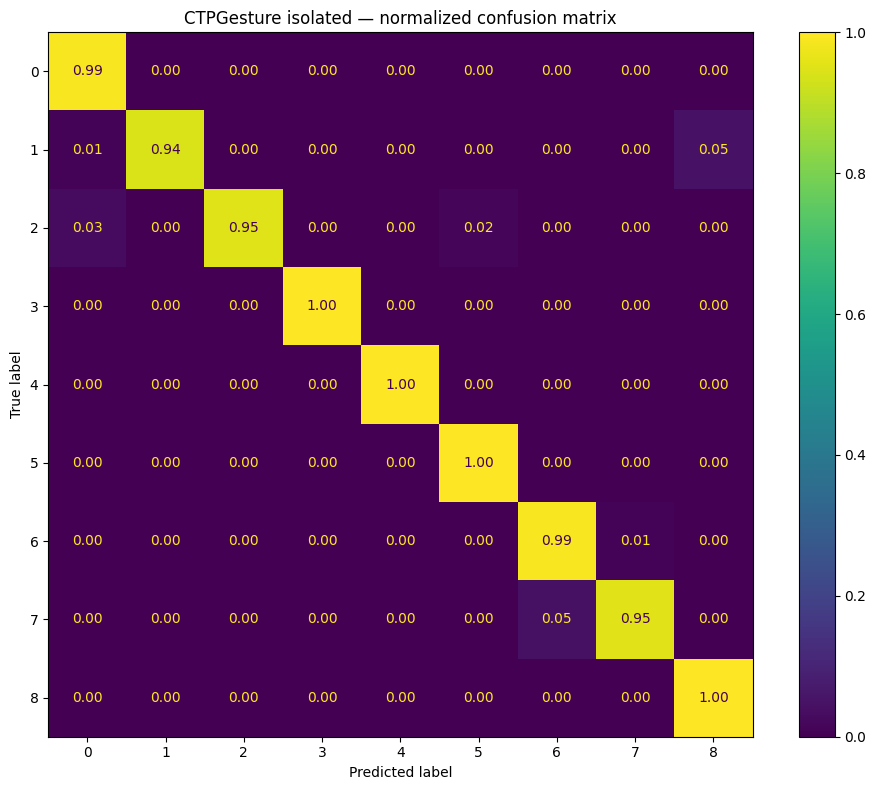

In [8]:
import time
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

def classification_metric_dict(
    y_true,
    y_pred,
    labels_for_macro,
):
    return {
        "accuracy": float(
            accuracy_score(y_true, y_pred)
        ),
        "balanced_accuracy": float(
            balanced_accuracy_score(
                y_true,
                y_pred,
            )
        ),
        "macro_precision": float(
            precision_score(
                y_true,
                y_pred,
                labels=labels_for_macro,
                average="macro",
                zero_division=0,
            )
        ),
        "macro_recall": float(
            recall_score(
                y_true,
                y_pred,
                labels=labels_for_macro,
                average="macro",
                zero_division=0,
            )
        ),
        "macro_f1": float(
            f1_score(
                y_true,
                y_pred,
                labels=labels_for_macro,
                average="macro",
                zero_division=0,
            )
        ),
        "weighted_f1": float(
            f1_score(
                y_true,
                y_pred,
                labels=labels_for_macro,
                average="weighted",
                zero_division=0,
            )
        ),
    }

def run_isolated_video_sequential(
    model,
    video_df,
    batch_size=ISOLATED_BATCH_SIZE,
):
    """
    Decode each video sequentially ONCE.

    Segments in CTPGesture are contiguous and time ordered, so there is no need
    to reopen the MP4 or seek randomly for every isolated sample.
    """
    video_df = (
        video_df
        .sort_values(["t_start", "t_end"])
        .reset_index(drop=True)
    )

    video_path = str(
        video_df.iloc[0]["video_path"]
    )

    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        raise RuntimeError(
            f"Cannot open video: {video_path}"
        )

    current_frame_idx = 0
    pending_clips = []
    pending_meta = []
    output_records = []

    decode_preprocess_sec = 0.0
    model_forward_sec = 0.0

    def flush_pending():
        nonlocal pending_clips
        nonlocal pending_meta
        nonlocal model_forward_sec
        nonlocal output_records

        if not pending_clips:
            return

        probs_batch, forward_sec = (
            clips_to_probabilities(
                model,
                pending_clips,
                DEVICE,
            )
        )

        model_forward_sec += forward_sec

        for meta, probs in zip(
            pending_meta,
            probs_batch,
        ):
            pred_idx = int(
                np.argmax(probs)
            )
            conf = float(
                probs[pred_idx]
            )

            record = {
                **meta,
                "pred_idx": pred_idx,
                "pred_name": (
                    CLASS_DESCRIPTIONS[
                        pred_idx
                    ]
                ),
                "confidence": conf,
                "correct": (
                    pred_idx
                    == meta["gt_idx"]
                ),
            }

            for class_idx, prob in enumerate(
                probs
            ):
                record[
                    f"prob_{class_idx}"
                ] = float(prob)

            output_records.append(record)

        pending_clips = []
        pending_meta = []

    for row in video_df.itertuples(
        index=False
    ):
        start_f = int(row.t_start)
        end_f = int(row.t_end)

        clip_len = (
            end_f - start_f + 1
        )

        rel_idx = sample_indices(
            clip_len,
            NUM_FRAMES,
        )

        target_idx = (
            start_f + rel_idx
        ).astype(np.int64)

        # Because segments are processed chronologically, decode forward only.
        target_unique = set(
            target_idx.tolist()
        )
        frame_tensor_by_idx = {}

        t_decode = time.perf_counter()

        while (
            current_frame_idx
            <= int(target_idx.max())
        ):
            ok, frame_bgr = cap.read()

            if not ok:
                break

            if current_frame_idx in target_unique:
                frame_rgb = cv2.cvtColor(
                    frame_bgr,
                    cv2.COLOR_BGR2RGB,
                )

                frame_tensor_by_idx[
                    current_frame_idx
                ] = preprocess_rgb_frame(
                    frame_rgb
                )

            current_frame_idx += 1

        decode_preprocess_sec += (
            time.perf_counter()
            - t_decode
        )

        if not frame_tensor_by_idx:
            raise RuntimeError(
                f"No sampled frames decoded "
                f"for {row.sample_id}"
            )

        # Duplicate rounded indices are allowed.
        frames = []
        last_tensor = None

        for idx in target_idx.tolist():
            if idx in frame_tensor_by_idx:
                tensor = frame_tensor_by_idx[
                    idx
                ]
                last_tensor = tensor
            elif last_tensor is not None:
                tensor = last_tensor
            else:
                # This should not normally happen.
                tensor = next(
                    iter(
                        frame_tensor_by_idx
                        .values()
                    )
                )

            frames.append(tensor)

        clip = (
            torch.stack(frames, dim=0)
            .permute(1, 0, 2, 3)
            .contiguous()
        )

        pending_clips.append(clip)
        pending_meta.append({
            "sample_id": row.sample_id,
            "video_id": row.video_id,
            "t_start": start_f,
            "t_end": end_f,
            "duration_frames": int(
                row.duration_frames
            ),
            "gt_idx": int(row.label),
            "gt_name": (
                CLASS_DESCRIPTIONS[
                    int(row.label)
                ]
            ),
        })

        if (
            len(pending_clips)
            >= int(batch_size)
        ):
            flush_pending()

    flush_pending()
    cap.release()

    return (
        output_records,
        decode_preprocess_sec,
        model_forward_sec,
    )

isolated_results = None
isolated_all_metrics = None
isolated_gesture_metrics = None

if RUN_ISOLATED:
    isolated_df = test_segments.copy()

    if ISOLATED_MAX_SAMPLES is not None:
        isolated_df = isolated_df.iloc[
            :int(ISOLATED_MAX_SAMPLES)
        ].copy()

    all_records = []
    total_decode_sec = 0.0
    total_forward_sec = 0.0

    wall_t0 = time.perf_counter()

    for video_id, video_df in tqdm(
        list(
            isolated_df.groupby(
                "video_id",
                sort=False,
            )
        ),
        desc="Isolated videos",
    ):
        (
            records,
            decode_sec,
            forward_sec,
        ) = run_isolated_video_sequential(
            model,
            video_df,
            ISOLATED_BATCH_SIZE,
        )

        all_records.extend(records)
        total_decode_sec += decode_sec
        total_forward_sec += forward_sec

    isolated_wall_sec = (
        time.perf_counter()
        - wall_t0
    )

    isolated_results = pd.DataFrame(
        all_records
    )

    # Restore deterministic original segment order.
    isolated_results = (
        isolated_results
        .merge(
            isolated_df[
                ["sample_id"]
            ].reset_index().rename(
                columns={
                    "index": "_order"
                }
            ),
            on="sample_id",
            how="left",
        )
        .sort_values("_order")
        .drop(columns="_order")
        .reset_index(drop=True)
    )

    y_true_all = (
        isolated_results["gt_idx"]
        .to_numpy(dtype=np.int64)
    )
    y_pred_all = (
        isolated_results["pred_idx"]
        .to_numpy(dtype=np.int64)
    )

    isolated_all_metrics = (
        classification_metric_dict(
            y_true_all,
            y_pred_all,
            list(range(NUM_CLASSES)),
        )
    )

    gesture_mask = (
        isolated_results["gt_idx"] != 0
    )

    y_true_gesture = (
        isolated_results.loc[
            gesture_mask,
            "gt_idx",
        ].to_numpy(dtype=np.int64)
    )
    y_pred_gesture = (
        isolated_results.loc[
            gesture_mask,
            "pred_idx",
        ].to_numpy(dtype=np.int64)
    )

    isolated_gesture_metrics = (
        classification_metric_dict(
            y_true_gesture,
            y_pred_gesture,
            list(range(1, NUM_CLASSES)),
        )
    )

    print("=" * 72)
    print("ISOLATED — ALL CLASSES")
    print("=" * 72)
    print("Samples:", len(y_true_all))
    for key, value in isolated_all_metrics.items():
        print(
            f"{key:20s}: {value:.6f}"
        )

    print()
    print("=" * 72)
    print(
        "ISOLATED — GESTURE ONLY "
        "(GT classes 1..8)"
    )
    print("=" * 72)
    print("Samples:", len(y_true_gesture))
    for key, value in (
        isolated_gesture_metrics.items()
    ):
        print(
            f"{key:20s}: {value:.6f}"
        )

    print()
    print("Timing")
    print(
        f"  wall time          : "
        f"{isolated_wall_sec:.1f} s"
    )
    print(
        f"  decode/preprocess  : "
        f"{total_decode_sec:.1f} s"
    )
    print(
        f"  model forward      : "
        f"{total_forward_sec:.1f} s"
    )

    isolated_report = (
        classification_report(
            y_true_all,
            y_pred_all,
            labels=list(
                range(NUM_CLASSES)
            ),
            target_names=CLASS_NAMES,
            output_dict=True,
            digits=4,
            zero_division=0,
        )
    )

    isolated_report_df = pd.DataFrame(
        isolated_report
    ).T

    display(isolated_report_df)

    cm = confusion_matrix(
        y_true_all,
        y_pred_all,
        labels=list(
            range(NUM_CLASSES)
        ),
        normalize="true",
    )

    fig, ax = plt.subplots(
        figsize=(10, 8)
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=CLASS_CODES,
    ).plot(
        ax=ax,
        values_format=".2f",
        colorbar=True,
    )

    ax.set_title(
        "CTPGesture isolated — "
        "normalized confusion matrix"
    )
    plt.tight_layout()
    plt.show()

    isolated_results.to_csv(
        OUTPUT_DIR
        / "isolated_predictions.csv",
        index=False,
    )

    isolated_report_df.to_csv(
        OUTPUT_DIR
        / "isolated_classification_report.csv"
    )

else:
    print("[SKIP] RUN_ISOLATED=False")

## 7. Continuous gesture recognition helpers

Continuous evaluation never uses ground-truth segment boundaries for model
input construction.

Only the full video is used to generate sliding windows.

For CTPGesture:

```text
WINDOW_SIZE = 32
WINDOW_STEP = 8
overlap     = 75%
MODEL_FRAMES = 16
offsets = [0,2,4,...,30]
```

Each window produces one 9-class probability vector. Every frame receives the
average probability of all windows covering it.

The raw frame prediction is then:

\[
\hat y_f = \arg\max_c P(c|f)
\]

Ground truth from the CSV is used only for scoring.

In [9]:
import time
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

def get_video_info(video_path):
    cap = cv2.VideoCapture(
        str(video_path)
    )

    if not cap.isOpened():
        raise ValueError(
            f"Cannot open video: {video_path}"
        )

    total_frames = int(
        cap.get(cv2.CAP_PROP_FRAME_COUNT)
    )
    fps = float(
        cap.get(cv2.CAP_PROP_FPS)
    )

    cap.release()

    if fps <= 0:
        fps = 15.0

    return total_frames, fps

def build_window_starts(
    total_frames,
    window_size,
    window_step,
):
    if total_frames <= window_size:
        return [0]

    last_full_start = (
        total_frames - window_size
    )

    starts = list(
        range(
            0,
            last_full_start + 1,
            window_step,
        )
    )

    if starts[-1] != last_full_start:
        starts.append(
            last_full_start
        )

    return starts

def build_sample_offsets(
    window_size,
    model_frames,
):
    assert (
        window_size % model_frames == 0
    )

    stride = (
        window_size // model_frames
    )

    offsets = np.arange(
        0,
        window_size,
        stride,
        dtype=np.int64,
    )

    assert len(offsets) == model_frames
    return offsets

def _build_window_target_indices(
    starts,
    sample_offsets,
    total_frames,
):
    targets = []

    for start in starts:
        idxs = np.clip(
            int(start) + sample_offsets,
            0,
            total_frames - 1,
        ).astype(np.int64)
        targets.append(idxs)

    return targets

def run_continuous_inference(
    model,
    video_id,
    show_progress=False,
    batch_size=CONTINUOUS_BATCH_SIZE,
):
    """
    Optimized continuous inference.

    Key properties:
    - MP4 is opened exactly once per video.
    - Frames are decoded sequentially.
    - No CAP_PROP_POS_FRAMES random seeks.
    - Overlapping windows reuse already-preprocessed frames.
    - Multiple windows are evaluated in one GPU forward pass.
    """
    video_path = (
        TEST_DIR / f"{video_id}.mp4"
    )
    csv_path = (
        TEST_DIR / f"{video_id}.csv"
    )

    gt_labels = read_ctp_labels(
        csv_path
    )

    total_frames_video, fps = (
        get_video_info(video_path)
    )

    usable_frames = min(
        total_frames_video,
        len(gt_labels),
    )

    gt_labels = gt_labels[
        :usable_frames
    ]
    total_frames = usable_frames

    starts = build_window_starts(
        total_frames,
        WINDOW_SIZE,
        WINDOW_STEP,
    )

    ends = [
        min(
            start + WINDOW_SIZE - 1,
            total_frames - 1,
        )
        for start in starts
    ]

    sample_offsets = (
        build_sample_offsets(
            WINDOW_SIZE,
            MODEL_FRAMES,
        )
    )

    window_targets = (
        _build_window_target_indices(
            starts,
            sample_offsets,
            total_frames,
        )
    )

    # Count how many future windows still need each frame.
    # This allows a small rolling frame cache even with overlap.
    from collections import Counter

    use_count = Counter()

    for target_idx in window_targets:
        use_count.update(
            target_idx.tolist()
        )

    needed_indices = set(
        use_count.keys()
    )

    frame_cache = {}

    cap = cv2.VideoCapture(
        str(video_path)
    )

    if not cap.isOpened():
        raise RuntimeError(
            f"Cannot open video: {video_path}"
        )

    current_frame_idx = 0

    p_raw = np.zeros(
        (
            len(starts),
            NUM_CLASSES,
        ),
        dtype=np.float32,
    )

    pending_clips = []
    pending_window_indices = []

    decode_preprocess_sec = 0.0
    model_forward_sec = 0.0

    wall_t0 = time.perf_counter()

    if show_progress:
        progress = tqdm(
            total=len(starts),
            desc=f"Continuous {video_id}",
        )
    else:
        progress = None

    def flush_batch():
        nonlocal pending_clips
        nonlocal pending_window_indices
        nonlocal model_forward_sec

        if not pending_clips:
            return

        probs_batch, forward_sec = (
            clips_to_probabilities(
                model,
                pending_clips,
                DEVICE,
            )
        )

        model_forward_sec += forward_sec

        for wi, probs in zip(
            pending_window_indices,
            probs_batch,
        ):
            p_raw[wi] = probs

        if progress is not None:
            progress.update(
                len(pending_clips)
            )

        pending_clips = []
        pending_window_indices = []

    for wi, target_idx in enumerate(
        window_targets
    ):
        max_target = int(
            target_idx.max()
        )

        t_decode = time.perf_counter()

        # Sequential decode only until this window's newest required frame.
        while (
            current_frame_idx
            <= max_target
        ):
            ok, frame_bgr = cap.read()

            if not ok:
                break

            if (
                current_frame_idx
                in needed_indices
            ):
                frame_rgb = cv2.cvtColor(
                    frame_bgr,
                    cv2.COLOR_BGR2RGB,
                )

                frame_cache[
                    current_frame_idx
                ] = preprocess_rgb_frame(
                    frame_rgb
                )

            current_frame_idx += 1

        decode_preprocess_sec += (
            time.perf_counter()
            - t_decode
        )

        missing = [
            int(idx)
            for idx in target_idx
            if int(idx)
            not in frame_cache
        ]

        if missing:
            cap.release()
            if progress is not None:
                progress.close()

            raise RuntimeError(
                f"{video_id}: missing decoded "
                f"sample frames {missing[:8]}"
            )

        frames = [
            frame_cache[
                int(idx)
            ]
            for idx in target_idx
        ]

        clip = (
            torch.stack(frames, dim=0)
            .permute(1, 0, 2, 3)
            .contiguous()
        )

        pending_clips.append(clip)
        pending_window_indices.append(wi)

        # This window has consumed its references. Drop frames as soon as
        # no future overlapping window needs them.
        for idx in target_idx.tolist():
            idx = int(idx)
            use_count[idx] -= 1

            if use_count[idx] <= 0:
                use_count.pop(idx, None)
                frame_cache.pop(
                    idx,
                    None,
                )
                needed_indices.discard(
                    idx
                )

        if (
            len(pending_clips)
            >= int(batch_size)
        ):
            flush_batch()

    flush_batch()

    if progress is not None:
        progress.close()

    cap.release()

    wall_elapsed = (
        time.perf_counter()
        - wall_t0
    )

    gt_segments = gesture_segments(
        gt_labels
    )

    return {
        "video_id": video_id,
        "video_path": str(video_path),
        "csv_path": str(csv_path),
        "fps": float(fps),
        "total_frames": int(total_frames),
        "duration_sec": float(
            total_frames / fps
        ),
        "window_starts": np.asarray(
            starts,
            dtype=np.int64,
        ),
        "window_ends": np.asarray(
            ends,
            dtype=np.int64,
        ),
        "sample_offsets": np.asarray(
            sample_offsets,
            dtype=np.int64,
        ),
        "num_windows": int(
            len(starts)
        ),
        "P_raw": p_raw,
        "gt_labels": gt_labels,
        "gt_segments": gt_segments,

        # New timing fields with unambiguous names.
        "wall_elapsed_sec": float(
            wall_elapsed
        ),
        "decode_preprocess_sec": float(
            decode_preprocess_sec
        ),
        "model_forward_sec": float(
            model_forward_sec
        ),
        "mean_wall_sec_per_window": (
            float(
                wall_elapsed
                / len(starts)
            )
            if starts
            else np.nan
        ),
        "mean_model_sec_per_window": (
            float(
                model_forward_sec
                / len(starts)
            )
            if starts
            else np.nan
        ),

        # Backward-compatible names used by later cells.
        "infer_elapsed_sec": float(
            wall_elapsed
        ),
        "mean_infer_sec_per_window": (
            float(
                wall_elapsed
                / len(starts)
            )
            if starts
            else np.nan
        ),
    }

def smooth_window_probs(
    window_probs,
    enabled=False,
):
    if (
        not enabled
        or len(window_probs) <= 1
    ):
        return np.asarray(
            window_probs,
            dtype=np.float32,
        ).copy()

    padded = np.pad(
        window_probs,
        ((1, 1), (0, 0)),
        mode="edge",
    )

    return (
        (
            padded[:-2]
            + padded[1:-1]
            + padded[2:]
        )
        / 3.0
    ).astype(np.float32)

def windows_to_frame_probs(
    window_probs,
    window_starts,
    window_ends,
    total_frames,
    num_classes=NUM_CLASSES,
):
    p_sum = np.zeros(
        (total_frames, num_classes),
        dtype=np.float64,
    )

    count = np.zeros(
        total_frames,
        dtype=np.float64,
    )

    for i, start in enumerate(
        window_starts
    ):
        end = int(
            window_ends[i]
        )

        p_sum[
            start:end + 1
        ] += window_probs[i]

        count[
            start:end + 1
        ] += 1.0

    uncovered = count == 0

    if np.any(uncovered):
        count[uncovered] = 1.0
        p_sum[
            uncovered,
            0,
        ] = 1.0

    return (
        p_sum / count[:, None]
    ).astype(np.float32)

def labels_to_segments(labels):
    labels = np.asarray(
        labels,
        dtype=np.int64,
    )

    if len(labels) == 0:
        return []

    segments = []
    start = 0
    current = int(labels[0])

    for i in range(1, len(labels)):
        value = int(labels[i])

        if value != current:
            segments.append({
                "label": current,
                "start": start,
                "end": i - 1,
            })
            start = i
            current = value

    segments.append({
        "label": current,
        "start": start,
        "end": len(labels) - 1,
    })

    return segments

def gesture_segments(labels):
    return [
        seg
        for seg in labels_to_segments(labels)
        if int(seg["label"]) != 0
    ]

def link_same_label_across_gaps(
    frame_labels,
    max_gap_frames,
    fps,
):
    linked = np.asarray(
        frame_labels,
        dtype=np.int64,
    ).copy()

    log = []

    while True:
        segs = labels_to_segments(
            linked
        )

        candidates = []

        for i, left in enumerate(segs):
            label = int(
                left["label"]
            )

            if label == 0:
                continue

            for j in range(
                i + 1,
                len(segs),
            ):
                right = segs[j]

                gap = int(
                    right["start"]
                    - left["end"]
                    - 1
                )

                if gap > max_gap_frames:
                    break

                if (
                    int(right["label"])
                    == label
                ):
                    if gap > 0:
                        candidates.append(
                            (
                                gap,
                                int(left["start"]),
                                i,
                                j,
                                label,
                            )
                        )
                    break

        if not candidates:
            break

        _, _, i, j, label = min(
            candidates,
            key=lambda x: (
                x[0],
                x[1],
            ),
        )

        segs = labels_to_segments(
            linked
        )

        left = segs[i]
        right = segs[j]

        gap_start = int(
            left["end"] + 1
        )
        gap_end = int(
            right["start"] - 1
        )

        old_labels = linked[
            gap_start:gap_end + 1
        ].copy()

        gap_frames = (
            gap_end
            - gap_start
            + 1
        )

        linked[
            gap_start:gap_end + 1
        ] = label

        log.append({
            "label": label,
            "gap_start": gap_start,
            "gap_end": gap_end,
            "gap_frames": gap_frames,
            "gap_sec": gap_frames / fps,
            "replaced_labels": sorted(
                np.unique(old_labels)
                .astype(int)
                .tolist()
            ),
        })

    return linked, log

def remove_short_gesture_segments(
    frame_labels,
    min_frames,
    fps,
    fill_same_neighbors=True,
):
    src = np.asarray(
        frame_labels,
        dtype=np.int64,
    )

    out = src.copy()
    segs = labels_to_segments(src)
    log = []

    for i, seg in enumerate(segs):
        label = int(
            seg["label"]
        )

        if label == 0:
            continue

        n_frames = int(
            seg["end"]
            - seg["start"]
            + 1
        )

        if n_frames >= min_frames:
            continue

        new_label = 0
        reason = "short_to_background"

        if (
            fill_same_neighbors
            and 0 < i < len(segs) - 1
        ):
            prev_seg = segs[i - 1]
            next_seg = segs[i + 1]

            prev_len = int(
                prev_seg["end"]
                - prev_seg["start"]
                + 1
            )

            next_len = int(
                next_seg["end"]
                - next_seg["start"]
                + 1
            )

            if (
                int(prev_seg["label"]) != 0
                and int(prev_seg["label"])
                == int(next_seg["label"])
                and prev_len >= min_frames
                and next_len >= min_frames
            ):
                new_label = int(
                    prev_seg["label"]
                )
                reason = (
                    "short_between_same_label"
                )

        out[
            int(seg["start"]):
            int(seg["end"]) + 1
        ] = new_label

        log.append({
            "start_frame": int(seg["start"]),
            "end_frame": int(seg["end"]),
            "duration_frames": n_frames,
            "duration_sec": n_frames / fps,
            "old_label": label,
            "new_label": new_label,
            "reason": reason,
        })

    return out, log

def temporal_iou(a, b):
    inter = max(
        min(a["end"], b["end"])
        - max(a["start"], b["start"])
        + 1,
        0,
    )

    union = (
        max(a["end"], b["end"])
        - min(a["start"], b["start"])
        + 1
    )

    return (
        0.0
        if union <= 0
        else inter / union
    )

def overlap_score(
    gt,
    pred,
    theta_frames,
):
    used = set()
    scores = []

    gt = sorted(
        gt,
        key=lambda x: x["start"],
    )
    pred = sorted(
        pred,
        key=lambda x: x["start"],
    )

    for g in gt:
        candidates = []

        for j, p in enumerate(pred):
            if (
                j in used
                or p["label"] != g["label"]
            ):
                continue

            if (
                abs(
                    p["start"] - g["start"]
                ) > theta_frames
            ):
                continue

            if (
                abs(
                    p["end"] - g["end"]
                ) > theta_frames
            ):
                continue

            candidates.append(
                (
                    temporal_iou(p, g),
                    j,
                )
            )

        if candidates:
            score, j = max(
                candidates,
                key=lambda x: x[0],
            )

            used.add(j)
            scores.append(score)
        else:
            scores.append(0.0)

    unmatched_pred = (
        len(pred) - len(used)
    )

    denom = (
        len(gt) + unmatched_pred
    )

    return (
        1.0
        if denom == 0
        else float(
            np.sum(scores) / denom
        )
    )

def gesture_recall_with_tolerance(
    gt,
    pred,
    theta_frames,
):
    gt = sorted(
        gt,
        key=lambda x: x["start"],
    )
    pred = sorted(
        pred,
        key=lambda x: x["start"],
    )

    if len(gt) == 0:
        return 1.0

    used = set()
    matched = 0

    for g in gt:
        candidates = []

        for j, p in enumerate(pred):
            if (
                j in used
                or int(p["label"])
                != int(g["label"])
            ):
                continue

            if (
                abs(
                    int(p["start"])
                    - int(g["start"])
                ) > theta_frames
            ):
                continue

            if (
                abs(
                    int(p["end"])
                    - int(g["end"])
                ) > theta_frames
            ):
                continue

            candidates.append(
                (
                    temporal_iou(p, g),
                    j,
                )
            )

        if candidates:
            _, best_j = max(
                candidates,
                key=lambda x: x[0],
            )
            used.add(best_j)
            matched += 1

    return matched / len(gt)

def frame_metric_dict(
    y_true,
    y_pred,
):
    return {
        "frame_accuracy": float(
            accuracy_score(
                y_true,
                y_pred,
            )
        ),
        "balanced_accuracy": float(
            balanced_accuracy_score(
                y_true,
                y_pred,
            )
        ),
        "macro_precision": float(
            precision_score(
                y_true,
                y_pred,
                labels=list(range(NUM_CLASSES)),
                average="macro",
                zero_division=0,
            )
        ),
        "macro_recall": float(
            recall_score(
                y_true,
                y_pred,
                labels=list(range(NUM_CLASSES)),
                average="macro",
                zero_division=0,
            )
        ),
        "macro_f1": float(
            f1_score(
                y_true,
                y_pred,
                labels=list(range(NUM_CLASSES)),
                average="macro",
                zero_division=0,
            )
        ),
        "weighted_f1": float(
            f1_score(
                y_true,
                y_pred,
                labels=list(range(NUM_CLASSES)),
                average="weighted",
                zero_division=0,
            )
        ),
    }

def apply_postprocess_to_cache(
    cache_entry,
    *,
    enable_smoothing=False,
    t_avg_sec=0.0,
    min_gesture_sec=0.0,
    fill_same_neighbors=False,
    theta_sec=THETA_SEC,
):
    fps = float(
        cache_entry["fps"]
    )

    total_frames = int(
        cache_entry["total_frames"]
    )

    starts = np.asarray(
        cache_entry["window_starts"],
        dtype=np.int64,
    )

    ends = np.asarray(
        cache_entry["window_ends"],
        dtype=np.int64,
    )

    p_raw = np.asarray(
        cache_entry["P_raw"],
        dtype=np.float32,
    )

    gt_labels = np.asarray(
        cache_entry["gt_labels"],
        dtype=np.int64,
    )

    gt_segments = [
        dict(seg)
        for seg in cache_entry["gt_segments"]
    ]

    p_stage = smooth_window_probs(
        p_raw,
        enabled=enable_smoothing,
    )

    p_frame = windows_to_frame_probs(
        p_stage,
        starts,
        ends,
        total_frames,
    )

    stage_labels = np.argmax(
        p_frame,
        axis=1,
    ).astype(np.int64)

    max_gap_frames = int(
        round(
            float(t_avg_sec) * fps
        )
    )

    min_frames = int(
        round(
            float(min_gesture_sec) * fps
        )
    )

    theta_frames = int(
        round(
            float(theta_sec) * fps
        )
    )

    linked_labels, linking_log = (
        link_same_label_across_gaps(
            stage_labels,
            max_gap_frames,
            fps,
        )
    )

    final_labels, removal_log = (
        remove_short_gesture_segments(
            linked_labels,
            min_frames,
            fps,
            fill_same_neighbors=(
                fill_same_neighbors
            ),
        )
    )

    pred_segments = gesture_segments(
        final_labels
    )

    metrics = frame_metric_dict(
        gt_labels,
        final_labels,
    )

    metrics.update({
        "temporal_overlap": overlap_score(
            gt_segments,
            pred_segments,
            theta_frames,
        ),
        "gesture_recall": (
            gesture_recall_with_tolerance(
                gt_segments,
                pred_segments,
                theta_frames,
            )
        ),
        "pred_segments": int(
            len(pred_segments)
        ),
        "gt_segments": int(
            len(gt_segments)
        ),
        "link_operations": int(
            len(linking_log)
        ),
        "removal_changes": int(
            len(removal_log)
        ),
        "correct_frames": int(
            np.sum(
                final_labels
                == gt_labels
            )
        ),
        "total_frames": int(
            len(gt_labels)
        ),
    })

    return {
        "metrics": metrics,
        "final_labels": final_labels,
        "stage_labels": stage_labels,
        "p_frame": p_frame,
        "pred_segments": pred_segments,
        "linking_log": linking_log,
        "removal_log": removal_log,
    }

print("[OK] Continuous helpers ready.")
print(
    "Sample offsets:",
    build_sample_offsets(
        WINDOW_SIZE,
        MODEL_FRAMES,
    ).tolist(),
)

[OK] Continuous helpers ready.
Sample offsets: [0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30]


### 7.1 One-video continuous debug

In [10]:
import pickle
import matplotlib.pyplot as plt

debug_cache = None

if RUN_CONTINUOUS and RUN_DEBUG_VIDEO:
    debug_cache_path = (
        PER_VIDEO_CACHE_DIR
        / f"{DEBUG_VIDEO_ID}_raw.pkl"
    )

    if (
        REUSE_PER_VIDEO_CACHE
        and debug_cache_path.is_file()
    ):
        print(
            "[CACHE] Loading debug video:",
            debug_cache_path,
        )

        with debug_cache_path.open(
            "rb"
        ) as f:
            debug_cache = pickle.load(f)

    else:
        debug_cache = (
            run_continuous_inference(
                model,
                DEBUG_VIDEO_ID,
                show_progress=True,
                batch_size=(
                    CONTINUOUS_BATCH_SIZE
                ),
            )
        )

        if SAVE_PER_VIDEO_CACHE:
            with debug_cache_path.open(
                "wb"
            ) as f:
                pickle.dump(
                    debug_cache,
                    f,
                    protocol=pickle.HIGHEST_PROTOCOL,
                )

    debug_raw = (
        apply_postprocess_to_cache(
            debug_cache,
            enable_smoothing=False,
            t_avg_sec=0.0,
            min_gesture_sec=0.0,
            fill_same_neighbors=False,
        )
    )

    debug_metrics = (
        debug_raw["metrics"]
    )

    print("=" * 72)
    print(
        f"CONTINUOUS DEBUG — "
        f"{DEBUG_VIDEO_ID}"
    )
    print("=" * 72)

    print(
        "Frames             :",
        debug_cache["total_frames"],
    )
    print(
        "FPS                :",
        debug_cache["fps"],
    )
    print(
        "Windows            :",
        debug_cache["num_windows"],
    )
    print(
        "Wall sec           :",
        f'{debug_cache["wall_elapsed_sec"]:.2f}',
    )
    print(
        "Decode/preproc sec :",
        f'{debug_cache["decode_preprocess_sec"]:.2f}',
    )
    print(
        "Model forward sec  :",
        f'{debug_cache["model_forward_sec"]:.2f}',
    )
    print(
        "Wall ms/window     :",
        f'{1000*debug_cache["mean_wall_sec_per_window"]:.3f}',
    )
    print(
        "Model ms/window    :",
        f'{1000*debug_cache["mean_model_sec_per_window"]:.3f}',
    )

    for key, value in (
        debug_metrics.items()
    ):
        if isinstance(
            value,
            (float, np.floating),
        ):
            print(
                f"{key:20s}: "
                f"{value:.6f}"
            )

    x = np.arange(
        debug_cache["total_frames"]
    )

    fig, axes = plt.subplots(
        2,
        1,
        figsize=(16, 6),
        sharex=True,
    )

    axes[0].plot(
        x,
        debug_cache["gt_labels"],
    )
    axes[0].set_ylabel(
        "Ground truth"
    )

    axes[1].plot(
        x,
        debug_raw["final_labels"],
    )
    axes[1].set_ylabel(
        "Raw prediction"
    )
    axes[1].set_xlabel(
        "Frame"
    )

    for ax in axes:
        ax.grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

elif RUN_CONTINUOUS:
    print(
        "[SKIP] Separate debug pass disabled. "
        "The full test will evaluate each video once."
    )
else:
    print("[SKIP] RUN_CONTINUOUS=False")

[SKIP] Separate debug pass disabled. The full test will evaluate each video once.


### 7.2 Full official continuous test split

This cell runs VideoMamba inference **once** over the official 11 test videos and
stores the raw window probabilities.

The resulting cache is reused by the post-processing ablation section, so the
model is not re-run for every threshold configuration.

Official continuous videos:   0%|          | 0/11 [00:00<?, ?it/s]

[002] source=fresh | windows=1345 | wall=151.4s | decode=76.9s | model=65.0s
[004] source=fresh | windows=534 | wall=61.1s | decode=31.4s | model=25.8s
[008] source=fresh | windows=720 | wall=83.2s | decode=42.6s | model=34.7s
[010] source=fresh | windows=654 | wall=76.5s | decode=39.5s | model=31.4s
[012] source=fresh | windows=782 | wall=90.1s | decode=45.9s | model=37.7s
[014] source=fresh | windows=825 | wall=98.0s | decode=51.3s | model=39.7s
[016] source=fresh | windows=817 | wall=95.7s | decode=49.4s | model=39.3s
[018] source=fresh | windows=714 | wall=84.6s | decode=44.0s | model=34.4s
[101] source=fresh | windows=719 | wall=81.8s | decode=41.5s | model=34.7s
[102] source=fresh | windows=671 | wall=76.3s | decode=38.6s | model=32.3s
[104] source=fresh | windows=611 | wall=69.4s | decode=34.8s | model=29.4s
CONTINUOUS RAW — OFFICIAL TEST SPLIT
videos                          : 11
frames                          : 67356
windows                         : 8392
mean_per_video_frame

,video_id,cache_source,frames,fps,duration_sec,windows,wall_sec,decode_preprocess_sec,model_forward_sec,wall_ms_per_window,...,macro_f1,weighted_f1,temporal_overlap,gesture_recall,pred_segments,gt_segments,link_operations,removal_changes,correct_frames,total_frames
0,002,fresh,10780,15.0,718.666667,1345,151.421957,76.940162,64.957307,112.581381,...,0.846244,0.901036,0.673491,0.950000,84,80,0,0,9701,10780
1,004,fresh,4291,15.0,286.066667,534,61.084640,31.370551,25.753373,114.390712,...,0.872820,0.892578,0.761775,0.980000,49,50,0,0,3827,4291
2,008,fresh,5781,15.0,385.400000,720,83.174354,42.613402,34.684017,115.519936,...,0.780885,0.819853,0.643465,1.000000,80,80,0,0,4722,5781
3,010,fresh,5252,15.0,350.133333,654,76.474505,39.536111,31.398973,116.933494,...,0.787235,0.831936,0.620349,0.958333,74,72,0,0,4357,5252
4,012,fresh,6274,15.0,418.266667,782,90.135713,45.884034,37.677925,115.263060,...,0.816285,0.856337,0.694758,0.931818,82,88,0,0,5402,6274
5,014,fresh,6621,15.0,441.400000,825,97.985042,51.259802,39.734458,118.769748,...,0.799254,0.822074,0.650332,0.865854,73,82,0,0,5514,6621
6,016,fresh,6558,15.0,437.200000,817,95.681597,49.415787,39.305026,117.113338,...,0.829743,0.844168,0.682182,0.987500,84,80,0,0,5532,6558
7,018,fresh,5729,15.0,381.933333,714,84.574407,44.027265,34.363357,118.451550,...,0.772286,0.813077,0.649156,0.888889,72,81,0,0,4706,5729
8,101,fresh,5775,15.0,385.000000,719,81.790288,41.483395,34.655602,113.755616,...,0.776349,0.815094,0.608791,0.950617,80,81,0,0,4711,5775
9,102,fresh,5388,15.0,359.200000,671,76.326836,38.556974,32.318500,113.750874,...,0.769776,0.795983,0.616210,0.975610,80,82,0,0,4283,5388


Saved combined cache: /kaggle/working/ctpgesture_videomamba_evaluation/continuous_raw_cache.pkl


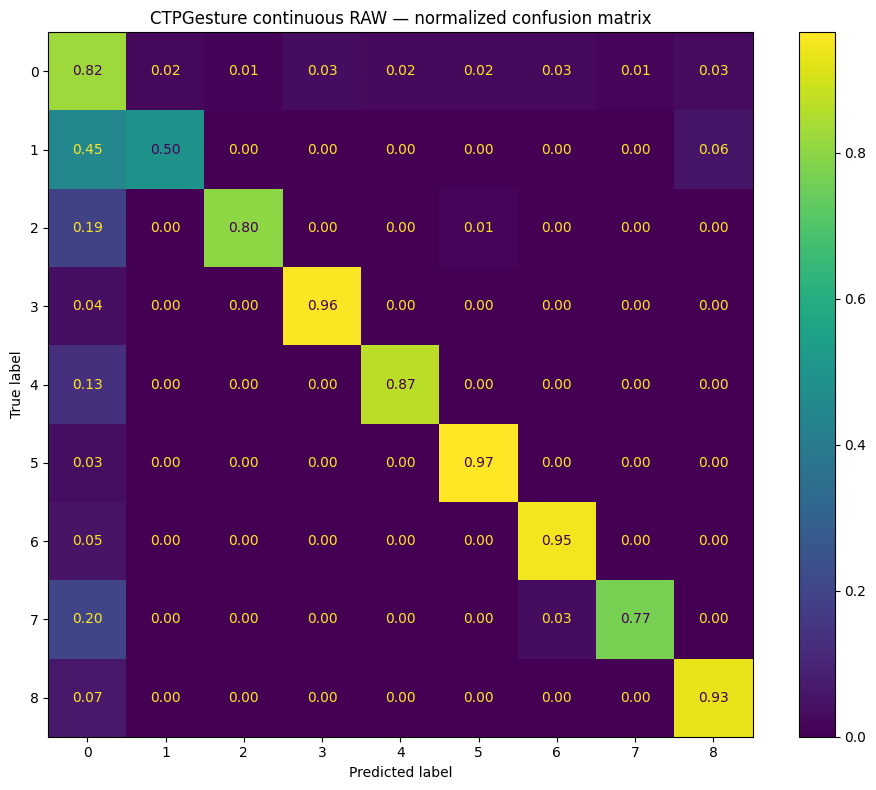

In [11]:
import pickle
from tqdm.auto import tqdm
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
)

continuous_raw_cache = {}
continuous_raw_rows = []
continuous_raw_summary = None

if RUN_CONTINUOUS:
    selected_ids = TEST_IDS.copy()

    if CONTINUOUS_MAX_VIDEOS is not None:
        selected_ids = selected_ids[
            :int(CONTINUOUS_MAX_VIDEOS)
        ]

    all_gt = []
    all_pred = []

    total_correct = 0
    total_frames = 0
    total_windows = 0

    total_wall_sec = 0.0
    total_decode_preprocess_sec = 0.0
    total_model_forward_sec = 0.0

    for video_id in tqdm(
        selected_ids,
        desc="Official continuous videos",
    ):
        cache_path = (
            PER_VIDEO_CACHE_DIR
            / f"{video_id}_raw.pkl"
        )

        cache_entry = None
        cache_source = "fresh"

        # Reuse the optional debug result rather than running video 002 twice.
        if (
            REUSE_DEBUG_CACHE
            and debug_cache is not None
            and video_id
            == debug_cache.get(
                "video_id"
            )
        ):
            cache_entry = debug_cache
            cache_source = "debug-cache"

        elif (
            REUSE_PER_VIDEO_CACHE
            and cache_path.is_file()
        ):
            with cache_path.open(
                "rb"
            ) as f:
                cache_entry = (
                    pickle.load(f)
                )
            cache_source = "disk-cache"

        if cache_entry is None:
            cache_entry = (
                run_continuous_inference(
                    model,
                    video_id,
                    show_progress=False,
                    batch_size=(
                        CONTINUOUS_BATCH_SIZE
                    ),
                )
            )

            if SAVE_PER_VIDEO_CACHE:
                with cache_path.open(
                    "wb"
                ) as f:
                    pickle.dump(
                        cache_entry,
                        f,
                        protocol=(
                            pickle.HIGHEST_PROTOCOL
                        ),
                    )

        continuous_raw_cache[
            video_id
        ] = cache_entry

        raw_result = (
            apply_postprocess_to_cache(
                cache_entry,
                enable_smoothing=False,
                t_avg_sec=0.0,
                min_gesture_sec=0.0,
                fill_same_neighbors=False,
                theta_sec=THETA_SEC,
            )
        )

        metrics = raw_result[
            "metrics"
        ]

        continuous_raw_rows.append({
            "video_id": video_id,
            "cache_source": cache_source,
            "frames": cache_entry[
                "total_frames"
            ],
            "fps": cache_entry[
                "fps"
            ],
            "duration_sec": cache_entry[
                "duration_sec"
            ],
            "windows": cache_entry[
                "num_windows"
            ],
            "wall_sec": cache_entry[
                "wall_elapsed_sec"
            ],
            "decode_preprocess_sec": (
                cache_entry[
                    "decode_preprocess_sec"
                ]
            ),
            "model_forward_sec": (
                cache_entry[
                    "model_forward_sec"
                ]
            ),
            "wall_ms_per_window": (
                1000
                * cache_entry[
                    "mean_wall_sec_per_window"
                ]
            ),
            "model_ms_per_window": (
                1000
                * cache_entry[
                    "mean_model_sec_per_window"
                ]
            ),
            **metrics,
        })

        gt = np.asarray(
            cache_entry["gt_labels"],
            dtype=np.int64,
        )

        pred = np.asarray(
            raw_result["final_labels"],
            dtype=np.int64,
        )

        all_gt.append(gt)
        all_pred.append(pred)

        total_correct += int(
            metrics["correct_frames"]
        )
        total_frames += int(
            metrics["total_frames"]
        )
        total_windows += int(
            cache_entry["num_windows"]
        )

        # Only fresh work should contribute to current-run execution-time
        # totals. Cached entries retain their original timings and are still
        # included below as protocol/runtime observations.
        total_wall_sec += float(
            cache_entry["wall_elapsed_sec"]
        )
        total_decode_preprocess_sec += float(
            cache_entry[
                "decode_preprocess_sec"
            ]
        )
        total_model_forward_sec += float(
            cache_entry[
                "model_forward_sec"
            ]
        )

        print(
            f"[{video_id}] "
            f"source={cache_source} | "
            f"windows={cache_entry['num_windows']} | "
            f"wall={cache_entry['wall_elapsed_sec']:.1f}s | "
            f"decode={cache_entry['decode_preprocess_sec']:.1f}s | "
            f"model={cache_entry['model_forward_sec']:.1f}s"
        )

    continuous_raw_df = pd.DataFrame(
        continuous_raw_rows
    )

    y_true_global = np.concatenate(
        all_gt
    )
    y_pred_global = np.concatenate(
        all_pred
    )

    global_metrics = frame_metric_dict(
        y_true_global,
        y_pred_global,
    )

    continuous_raw_summary = {
        "videos": int(
            len(continuous_raw_df)
        ),
        "frames": int(
            total_frames
        ),
        "windows": int(
            total_windows
        ),
        "mean_per_video_frame_accuracy": float(
            continuous_raw_df[
                "frame_accuracy"
            ].mean()
        ),
        "global_frame_accuracy": float(
            total_correct
            / total_frames
        ),
        "global_balanced_accuracy": float(
            global_metrics[
                "balanced_accuracy"
            ]
        ),
        "global_macro_precision": float(
            global_metrics[
                "macro_precision"
            ]
        ),
        "global_macro_recall": float(
            global_metrics[
                "macro_recall"
            ]
        ),
        "global_macro_f1": float(
            global_metrics[
                "macro_f1"
            ]
        ),
        "global_weighted_f1": float(
            global_metrics[
                "weighted_f1"
            ]
        ),
        "mean_temporal_overlap": float(
            continuous_raw_df[
                "temporal_overlap"
            ].mean()
        ),
        "mean_gesture_recall": float(
            continuous_raw_df[
                "gesture_recall"
            ].mean()
        ),
        "total_wall_sec": float(
            total_wall_sec
        ),
        "total_decode_preprocess_sec": float(
            total_decode_preprocess_sec
        ),
        "total_model_forward_sec": float(
            total_model_forward_sec
        ),
        "mean_wall_ms_per_window": float(
            1000
            * total_wall_sec
            / total_windows
        ),
        "mean_model_ms_per_window": float(
            1000
            * total_model_forward_sec
            / total_windows
        ),
        "effective_windows_per_second": float(
            total_windows
            / total_wall_sec
        ),
    }

    print("=" * 72)
    print(
        "CONTINUOUS RAW — "
        "OFFICIAL TEST SPLIT"
    )
    print("=" * 72)

    for key, value in (
        continuous_raw_summary.items()
    ):
        if isinstance(
            value,
            (float, np.floating),
        ):
            print(
                f"{key:32s}: "
                f"{value:.6f}"
            )
        else:
            print(
                f"{key:32s}: "
                f"{value}"
            )

    display(continuous_raw_df)

    continuous_raw_df.to_csv(
        OUTPUT_DIR
        / "continuous_raw_per_video.csv",
        index=False,
    )

    combined_cache_path = (
        OUTPUT_DIR
        / "continuous_raw_cache.pkl"
    )

    with combined_cache_path.open(
        "wb"
    ) as f:
        pickle.dump(
            continuous_raw_cache,
            f,
            protocol=pickle.HIGHEST_PROTOCOL,
        )

    print(
        "Saved combined cache:",
        combined_cache_path,
    )

    cm = confusion_matrix(
        y_true_global,
        y_pred_global,
        labels=list(
            range(NUM_CLASSES)
        ),
        normalize="true",
    )

    fig, ax = plt.subplots(
        figsize=(10, 8)
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=CLASS_CODES,
    ).plot(
        ax=ax,
        values_format=".2f",
        colorbar=True,
    )

    ax.set_title(
        "CTPGesture continuous RAW — "
        "normalized confusion matrix"
    )
    plt.tight_layout()
    plt.show()

else:
    print("[SKIP] RUN_CONTINUOUS=False")

### 7.3 Post-processing ablation

The model is **not run again** in this section.

The raw probability cache from Section 7.2 is reused to evaluate multiple
post-processing configurations.

Unlike the IPN-Hand notebook, CTPGesture has a large class-0 share, so the
default selection policy is:

1. maximize **global Macro-F1**;
2. use **mean Temporal Overlap** as a tie-breaker.

This avoids selecting a configuration merely because it predicts the dominant
background/attention class well.

In [12]:
import pickle
import time

POSTPROCESS_CACHE_PATH = (
    OUTPUT_DIR
    / "continuous_raw_cache.pkl"
)

PRIMARY_SELECTION_METRIC = (
    "global_macro_f1"
)
TIE_BREAK_METRIC = (
    "mean_temporal_overlap"
)

ALLOW_RAW_AS_BEST_LINK = True

LINK_THRESHOLDS_SEC = [
    0.3,
    0.7,
    1.0,
]

MIN_GESTURE_THRESHOLDS_SEC = [
    0.5,
    0.7,
    1.0,
    1.5,
]

if RUN_ABLATION:
    if (
        "continuous_raw_cache"
        not in globals()
        or not continuous_raw_cache
    ):
        if not POSTPROCESS_CACHE_PATH.is_file():
            raise FileNotFoundError(
                "Run Section 7.2 first. "
                f"Missing {POSTPROCESS_CACHE_PATH}"
            )

        with POSTPROCESS_CACHE_PATH.open(
            "rb"
        ) as f:
            continuous_raw_cache = (
                pickle.load(f)
            )

    def evaluate_postprocess_config(
        config
    ):
        t0 = time.perf_counter()

        per_video_rows = []
        all_gt = []
        all_pred = []

        total_correct = 0
        total_frames = 0
        total_pred_segments = 0
        total_gt_segments = 0
        total_links = 0
        total_removals = 0

        for (
            video_id,
            cache_entry,
        ) in continuous_raw_cache.items():

            result = (
                apply_postprocess_to_cache(
                    cache_entry,
                    enable_smoothing=config[
                        "smoothing"
                    ],
                    t_avg_sec=config[
                        "t_avg_sec"
                    ],
                    min_gesture_sec=config[
                        "min_gesture_sec"
                    ],
                    fill_same_neighbors=config[
                        "fill"
                    ],
                    theta_sec=THETA_SEC,
                )
            )

            metrics = result[
                "metrics"
            ]

            per_video_rows.append({
                "test": config["test"],
                "video_id": video_id,
                **metrics,
            })

            gt = np.asarray(
                cache_entry["gt_labels"],
                dtype=np.int64,
            )

            pred = np.asarray(
                result["final_labels"],
                dtype=np.int64,
            )

            all_gt.append(gt)
            all_pred.append(pred)

            total_correct += int(
                metrics["correct_frames"]
            )
            total_frames += int(
                metrics["total_frames"]
            )
            total_pred_segments += int(
                metrics["pred_segments"]
            )
            total_gt_segments += int(
                metrics["gt_segments"]
            )
            total_links += int(
                metrics["link_operations"]
            )
            total_removals += int(
                metrics["removal_changes"]
            )

        per_video_df = pd.DataFrame(
            per_video_rows
        )

        y_true = np.concatenate(
            all_gt
        )
        y_pred = np.concatenate(
            all_pred
        )

        global_metrics = frame_metric_dict(
            y_true,
            y_pred,
        )

        elapsed = (
            time.perf_counter() - t0
        )

        summary = {
            "test": config["test"],
            "smoothing": bool(
                config["smoothing"]
            ),
            "t_avg_sec": float(
                config["t_avg_sec"]
            ),
            "min_gesture_sec": float(
                config["min_gesture_sec"]
            ),
            "fill": bool(
                config["fill"]
            ),
            "videos": int(
                len(per_video_df)
            ),
            "mean_frame_accuracy": float(
                per_video_df[
                    "frame_accuracy"
                ].mean()
            ),
            "global_frame_accuracy": float(
                total_correct
                / total_frames
            ),
            "global_balanced_accuracy": float(
                global_metrics[
                    "balanced_accuracy"
                ]
            ),
            "global_macro_f1": float(
                global_metrics[
                    "macro_f1"
                ]
            ),
            "global_weighted_f1": float(
                global_metrics[
                    "weighted_f1"
                ]
            ),
            "mean_temporal_overlap": float(
                per_video_df[
                    "temporal_overlap"
                ].mean()
            ),
            "mean_gesture_recall": float(
                per_video_df[
                    "gesture_recall"
                ].mean()
            ),
            "total_gt_segments": int(
                total_gt_segments
            ),
            "total_pred_segments": int(
                total_pred_segments
            ),
            "total_link_operations": int(
                total_links
            ),
            "total_removal_changes": int(
                total_removals
            ),
            "postprocess_sec": float(
                elapsed
            ),
        }

        return summary, per_video_df

    def choose_best(
        summary_df,
        candidate_tests,
    ):
        candidates = summary_df[
            summary_df["test"].isin(
                candidate_tests
            )
        ].copy()

        if candidates.empty:
            raise ValueError(
                f"No candidates: {candidate_tests}"
            )

        candidates = candidates.sort_values(
            [
                PRIMARY_SELECTION_METRIC,
                TIE_BREAK_METRIC,
            ],
            ascending=[
                False,
                False,
            ],
        )

        return candidates.iloc[0]

    all_summaries = []
    all_per_video = []

    # ---------------------------------------------------------
    # Stage A: linking threshold sweep
    # ---------------------------------------------------------
    stage_a_configs = [
        {
            "test": "Raw",
            "smoothing": False,
            "t_avg_sec": 0.0,
            "min_gesture_sec": 0.0,
            "fill": False,
        },
        {
            "test": "L1",
            "smoothing": False,
            "t_avg_sec": 0.3,
            "min_gesture_sec": 0.0,
            "fill": False,
        },
        {
            "test": "L2",
            "smoothing": False,
            "t_avg_sec": 0.7,
            "min_gesture_sec": 0.0,
            "fill": False,
        },
        {
            "test": "L3",
            "smoothing": False,
            "t_avg_sec": 1.0,
            "min_gesture_sec": 0.0,
            "fill": False,
        },
    ]

    print(
        "\n=== Stage A: T_AVG sweep ==="
    )

    for cfg in stage_a_configs:
        summary, per_video = (
            evaluate_postprocess_config(
                cfg
            )
        )

        all_summaries.append(
            summary
        )
        all_per_video.append(
            per_video
        )

        print(
            f'{cfg["test"]:>3s} | '
            f'T_AVG={cfg["t_avg_sec"]:.1f}s | '
            f'MacroF1={summary["global_macro_f1"]:.6f} | '
            f'FrameAcc={summary["global_frame_accuracy"]:.6f} | '
            f'Overlap={summary["mean_temporal_overlap"]:.6f} | '
            f'Recall={summary["mean_gesture_recall"]:.6f}'
        )

    summary_df = pd.DataFrame(
        all_summaries
    )

    link_candidates = [
        "L1",
        "L2",
        "L3",
    ]

    if ALLOW_RAW_AS_BEST_LINK:
        link_candidates = [
            "Raw"
        ] + link_candidates

    best_link = choose_best(
        summary_df,
        link_candidates,
    )

    BEST_T_AVG_SEC = float(
        best_link["t_avg_sec"]
    )

    print(
        "\nBest linking config:",
        best_link["test"],
        "T_AVG=",
        BEST_T_AVG_SEC,
    )

    # ---------------------------------------------------------
    # Stage B: short-gesture removal sweep
    # ---------------------------------------------------------
    stage_b_configs = [
        {
            "test": f"R{i+1}",
            "smoothing": False,
            "t_avg_sec": BEST_T_AVG_SEC,
            "min_gesture_sec": threshold,
            "fill": False,
        }
        for i, threshold in enumerate(
            MIN_GESTURE_THRESHOLDS_SEC
        )
    ]

    print(
        "\n=== Stage B: MIN_GESTURE sweep ==="
    )

    for cfg in stage_b_configs:
        summary, per_video = (
            evaluate_postprocess_config(
                cfg
            )
        )

        all_summaries.append(
            summary
        )
        all_per_video.append(
            per_video
        )

        print(
            f'{cfg["test"]:>3s} | '
            f'MIN={cfg["min_gesture_sec"]:.1f}s | '
            f'MacroF1={summary["global_macro_f1"]:.6f} | '
            f'FrameAcc={summary["global_frame_accuracy"]:.6f} | '
            f'Overlap={summary["mean_temporal_overlap"]:.6f} | '
            f'Recall={summary["mean_gesture_recall"]:.6f}'
        )

    summary_df = pd.DataFrame(
        all_summaries
    )

    removal_candidates = [
        str(best_link["test"])
    ] + [
        cfg["test"]
        for cfg in stage_b_configs
    ]

    best_removal = choose_best(
        summary_df,
        removal_candidates,
    )

    BEST_MIN_GESTURE_SEC = float(
        best_removal[
            "min_gesture_sec"
        ]
    )

    # ---------------------------------------------------------
    # Stage C: fill same neighbors
    # ---------------------------------------------------------
    f1_cfg = {
        "test": "F1",
        "smoothing": False,
        "t_avg_sec": BEST_T_AVG_SEC,
        "min_gesture_sec": BEST_MIN_GESTURE_SEC,
        "fill": True,
    }

    print(
        "\n=== Stage C: Fill same neighbors ==="
    )

    summary, per_video = (
        evaluate_postprocess_config(
            f1_cfg
        )
    )

    all_summaries.append(
        summary
    )
    all_per_video.append(
        per_video
    )

    # ---------------------------------------------------------
    # Stage D: smoothing
    # ---------------------------------------------------------
    stage_d_configs = [
        {
            "test": "S1",
            "smoothing": True,
            "t_avg_sec": BEST_T_AVG_SEC,
            "min_gesture_sec": BEST_MIN_GESTURE_SEC,
            "fill": False,
        },
        {
            "test": "S2",
            "smoothing": True,
            "t_avg_sec": BEST_T_AVG_SEC,
            "min_gesture_sec": BEST_MIN_GESTURE_SEC,
            "fill": True,
        },
    ]

    print(
        "\n=== Stage D: Smoothing ==="
    )

    for cfg in stage_d_configs:
        summary, per_video = (
            evaluate_postprocess_config(
                cfg
            )
        )

        all_summaries.append(
            summary
        )
        all_per_video.append(
            per_video
        )

    postprocess_ablation_summary = (
        pd.DataFrame(
            all_summaries
        )
    )

    postprocess_ablation_per_video = (
        pd.concat(
            all_per_video,
            ignore_index=True,
        )
    )

    raw_row = (
        postprocess_ablation_summary[
            postprocess_ablation_summary[
                "test"
            ] == "Raw"
        ]
        .iloc[0]
    )

    for metric in [
        "global_frame_accuracy",
        "global_macro_f1",
        "mean_temporal_overlap",
        "mean_gesture_recall",
    ]:
        postprocess_ablation_summary[
            f"delta_{metric}_vs_raw"
        ] = (
            postprocess_ablation_summary[
                metric
            ]
            - float(raw_row[metric])
        )

    best_overall = choose_best(
        postprocess_ablation_summary,
        postprocess_ablation_summary[
            "test"
        ].tolist(),
    )

    print(
        "\n=== Complete CTPGesture post-processing ablation ==="
    )

    display(
        postprocess_ablation_summary
        .sort_values(
            [
                PRIMARY_SELECTION_METRIC,
                TIE_BREAK_METRIC,
            ],
            ascending=[
                False,
                False,
            ],
        )
        .reset_index(drop=True)
    )

    print(
        "\n=== Best overall configuration ==="
    )
    print(
        "Test               :",
        best_overall["test"],
    )
    print(
        "Smoothing          :",
        bool(
            best_overall["smoothing"]
        ),
    )
    print(
        "T_AVG_SEC          :",
        float(
            best_overall["t_avg_sec"]
        ),
    )
    print(
        "MIN_GESTURE_SEC    :",
        float(
            best_overall[
                "min_gesture_sec"
            ]
        ),
    )
    print(
        "FILL               :",
        bool(
            best_overall["fill"]
        ),
    )
    print(
        "Global Macro-F1    :",
        f'{best_overall["global_macro_f1"]:.6f}',
    )
    print(
        "Global Frame Acc.  :",
        f'{best_overall["global_frame_accuracy"]:.6f}',
    )
    print(
        "Temporal Overlap   :",
        f'{best_overall["mean_temporal_overlap"]:.6f}',
    )
    print(
        "Gesture Recall     :",
        f'{best_overall["mean_gesture_recall"]:.6f}',
    )

    postprocess_ablation_summary.to_csv(
        OUTPUT_DIR
        / "postprocess_ablation_summary.csv",
        index=False,
    )

    postprocess_ablation_per_video.to_csv(
        OUTPUT_DIR
        / "postprocess_ablation_per_video.csv",
        index=False,
    )

else:
    print("[SKIP] RUN_ABLATION=False")


=== Stage A: T_AVG sweep ===
Raw | T_AVG=0.0s | MacroF1=0.806135 | FrameAcc=0.839836 | Overlap=0.653223 | Recall=0.948035
 L1 | T_AVG=0.3s | MacroF1=0.806135 | FrameAcc=0.839836 | Overlap=0.653223 | Recall=0.948035
 L2 | T_AVG=0.7s | MacroF1=0.806041 | FrameAcc=0.839717 | Overlap=0.652570 | Recall=0.946772
 L3 | T_AVG=1.0s | MacroF1=0.806041 | FrameAcc=0.839717 | Overlap=0.652570 | Recall=0.946772

Best linking config: Raw T_AVG= 0.0

=== Stage B: MIN_GESTURE sweep ===
 R1 | MIN=0.5s | MacroF1=0.806135 | FrameAcc=0.839836 | Overlap=0.653223 | Recall=0.948035
 R2 | MIN=0.7s | MacroF1=0.806113 | FrameAcc=0.839762 | Overlap=0.658222 | Recall=0.944513
 R3 | MIN=1.0s | MacroF1=0.806254 | FrameAcc=0.839940 | Overlap=0.658979 | Recall=0.944513
 R4 | MIN=1.5s | MacroF1=0.796713 | FrameAcc=0.838485 | Overlap=0.648662 | Recall=0.903928

=== Stage C: Fill same neighbors ===

=== Stage D: Smoothing ===

=== Complete CTPGesture post-processing ablation ===


,test,smoothing,t_avg_sec,min_gesture_sec,fill,videos,mean_frame_accuracy,global_frame_accuracy,global_balanced_accuracy,global_macro_f1,...,mean_gesture_recall,total_gt_segments,total_pred_segments,total_link_operations,total_removal_changes,postprocess_sec,delta_global_frame_accuracy_vs_raw,delta_global_macro_f1_vs_raw,delta_mean_temporal_overlap_vs_raw,delta_mean_gesture_recall_vs_raw
0,R3,False,0.0,1.0,False,11,0.835100,0.839940,0.839159,0.806254,...,0.944513,859,824,0,12,0.200292,0.000104,0.000119,0.005756,-0.003521
1,F1,False,0.0,1.0,True,11,0.835100,0.839940,0.839159,0.806254,...,0.944513,859,824,0,12,0.203905,0.000104,0.000119,0.005756,-0.003521
2,Raw,False,0.0,0.0,False,11,0.834973,0.839836,0.840043,0.806135,...,0.948035,859,836,0,0,0.210693,0.000000,0.000000,0.000000,0.000000
3,L1,False,0.3,0.0,False,11,0.834973,0.839836,0.840043,0.806135,...,0.948035,859,836,0,0,0.203852,0.000000,0.000000,0.000000,0.000000
4,R1,False,0.0,0.5,False,11,0.834973,0.839836,0.840043,0.806135,...,0.948035,859,836,0,0,0.206062,0.000000,0.000000,0.000000,0.000000
5,R2,False,0.0,0.7,False,11,0.834892,0.839762,0.839124,0.806113,...,0.944513,859,825,0,11,0.203162,-0.000074,-0.000022,0.004998,-0.003521
6,L2,False,0.7,0.0,False,11,0.834835,0.839717,0.840020,0.806041,...,0.946772,859,835,1,0,0.202107,-0.000119,-0.000094,-0.000654,-0.001263
7,L3,False,1.0,0.0,False,11,0.834835,0.839717,0.840020,0.806041,...,0.946772,859,835,1,0,0.202440,-0.000119,-0.000094,-0.000654,-0.001263
8,S2,True,0.0,1.0,True,11,0.833261,0.838188,0.832889,0.797515,...,0.915713,859,795,0,30,0.196345,-0.001648,-0.008620,-0.003498,-0.032322
9,S1,True,0.0,1.0,False,11,0.833194,0.838069,0.832462,0.797085,...,0.915713,859,796,0,30,0.205290,-0.001767,-0.009050,-0.004732,-0.032322



=== Best overall configuration ===
Test               : R3
Smoothing          : False
T_AVG_SEC          : 0.0
MIN_GESTURE_SEC    : 1.0
FILL               : False
Global Macro-F1    : 0.806254
Global Frame Acc.  : 0.839940
Temporal Overlap   : 0.658979
Gesture Recall     : 0.944513


## 8. Model complexity and FP32 runtime

In [13]:
import numpy as np

def _conv_out_dim(
    size,
    kernel,
    stride,
    padding,
    dilation,
):
    return (
        (
            size
            + 2 * padding
            - dilation * (kernel - 1)
            - 1
        )
        // stride
        + 1
    )

def _tuple3(value):
    if isinstance(value, tuple):
        return value
    return (
        value,
        value,
        value,
    )

def selective_scan_flops(
    batch,
    seqlen,
    d_inner,
    d_state,
    with_D=True,
    with_Z=True,
):
    flops = (
        9
        * batch
        * seqlen
        * d_inner
        * d_state
    )

    if with_D:
        flops += (
            batch
            * seqlen
            * d_inner
        )

    if with_Z:
        flops += (
            batch
            * seqlen
            * d_inner
        )

    return int(flops)

def count_videomamba_flops(
    model_vm,
    input_shape,
):
    B, C, T, H, W = map(
        int,
        input_shape,
    )

    patch_conv = (
        model_vm.patch_embed.proj
    )

    kT, kH, kW = _tuple3(
        patch_conv.kernel_size
    )
    sT, sH, sW = _tuple3(
        patch_conv.stride
    )
    pT, pH, pW = _tuple3(
        patch_conv.padding
    )
    dT, dH, dW = _tuple3(
        patch_conv.dilation
    )

    out_T = _conv_out_dim(
        T,
        kT,
        sT,
        pT,
        dT,
    )
    out_H = _conv_out_dim(
        H,
        kH,
        sH,
        pH,
        dH,
    )
    out_W = _conv_out_dim(
        W,
        kW,
        sW,
        pW,
        dW,
    )

    patch_positions = (
        out_T
        * out_H
        * out_W
    )

    patch_flops = (
        B
        * patch_positions
        * patch_conv.out_channels
        * (
            patch_conv.in_channels
            // patch_conv.groups
        )
        * kT
        * kH
        * kW
    )

    # VideoMamba has one class token.
    L = patch_positions + 1

    totals = {
        "Patch embedding Conv3d": int(
            patch_flops
        ),
        "Mamba input projection": 0,
        "Bidirectional depthwise Conv1d": 0,
        "Bidirectional x projection": 0,
        "Bidirectional dt projection": 0,
        "Bidirectional selective scan": 0,
        "Mamba output projection": 0,
        "Classifier head": 0,
    }

    for layer in model_vm.layers:
        m = layer.mixer

        d_model = int(
            m.d_model
        )
        d_inner = int(
            m.d_inner
        )
        d_state = int(
            m.d_state
        )
        dt_rank = int(
            m.dt_rank
        )
        d_conv = int(
            m.d_conv
        )

        directions = (
            2
            if bool(
                getattr(
                    m,
                    "bimamba",
                    False,
                )
            )
            else 1
        )

        in_proj = (
            B
            * L
            * d_model
            * (2 * d_inner)
        )

        conv1d = (
            directions
            * B
            * L
            * d_inner
            * d_conv
        )

        x_proj_out = int(
            m.x_proj.weight.shape[0]
        )

        x_proj = (
            directions
            * B
            * L
            * d_inner
            * x_proj_out
        )

        dt_proj = (
            directions
            * B
            * L
            * dt_rank
            * d_inner
        )

        scan = (
            directions
            * selective_scan_flops(
                B,
                L,
                d_inner,
                d_state,
                with_D=True,
                with_Z=True,
            )
        )

        out_proj = (
            B
            * L
            * d_inner
            * d_model
        )

        totals[
            "Mamba input projection"
        ] += int(in_proj)

        totals[
            "Bidirectional depthwise Conv1d"
        ] += int(conv1d)

        totals[
            "Bidirectional x projection"
        ] += int(x_proj)

        totals[
            "Bidirectional dt projection"
        ] += int(dt_proj)

        totals[
            "Bidirectional selective scan"
        ] += int(scan)

        totals[
            "Mamba output projection"
        ] += int(out_proj)

    if isinstance(
        model_vm.head,
        torch.nn.Linear,
    ):
        totals[
            "Classifier head"
        ] = int(
            B
            * model_vm.head.in_features
            * model_vm.head.out_features
        )

    total_flops = int(
        sum(totals.values())
    )

    return {
        "total_flops": total_flops,
        "total_gflops": (
            total_flops / 1e9
        ),
        "tokens": L,
        "layers": len(
            model_vm.layers
        ),
        "breakdown": totals,
    }

def benchmark_model_runtime(
    model_vm,
    warmup=5,
    runs=20,
):
    result = {
        "mean_ms": np.nan,
        "median_ms": np.nan,
        "p95_ms": np.nan,
        "throughput_clips_s": np.nan,
        "forward_extra_peak_mib": np.nan,
    }

    if not torch.cuda.is_available():
        return result

    x = torch.randn(
        1,
        3,
        NUM_FRAMES,
        IMG_SIZE,
        IMG_SIZE,
        device=DEVICE,
        dtype=torch.float32,
    )

    with torch.inference_mode():
        _ = model_vm(x)

    torch.cuda.synchronize()

    with torch.inference_mode():
        for _ in range(warmup):
            _ = model_vm(x)

    torch.cuda.synchronize()

    times = []

    with torch.inference_mode():
        for _ in range(runs):
            starter = torch.cuda.Event(
                enable_timing=True
            )
            ender = torch.cuda.Event(
                enable_timing=True
            )

            starter.record()
            _ = model_vm(x)
            ender.record()

            torch.cuda.synchronize()

            times.append(
                starter.elapsed_time(
                    ender
                )
            )

    times = np.asarray(
        times,
        dtype=np.float64,
    )

    torch.cuda.empty_cache()
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()

    baseline_allocated = (
        torch.cuda.memory_allocated()
    )

    with torch.inference_mode():
        _ = model_vm(x)

    torch.cuda.synchronize()

    peak_allocated = (
        torch.cuda.max_memory_allocated()
    )

    forward_extra_peak = max(
        0,
        peak_allocated
        - baseline_allocated,
    )

    mean_ms = float(
        times.mean()
    )

    result.update({
        "mean_ms": mean_ms,
        "median_ms": float(
            np.median(times)
        ),
        "p95_ms": float(
            np.percentile(
                times,
                95,
            )
        ),
        "throughput_clips_s": (
            1000.0 / mean_ms
        ),
        "forward_extra_peak_mib": (
            forward_extra_peak
            / 1024**2
        ),
    })

    return result

model_complexity = None

if RUN_COMPLEXITY:
    input_shape = (
        1,
        3,
        NUM_FRAMES,
        IMG_SIZE,
        IMG_SIZE,
    )

    total_params = int(
        sum(
            p.numel()
            for p in model.parameters()
        )
    )

    flops = count_videomamba_flops(
        model,
        input_shape,
    )

    runtime = benchmark_model_runtime(
        model,
    )

    model_complexity = {
        "model": "VideoMamba-Tiny",
        "input_shape": list(
            input_shape
        ),
        "parameters": total_params,
        "parameters_m": (
            total_params / 1e6
        ),
        "fp32_parameter_mib": (
            total_params
            * 4
            / 1024**2
        ),
        "gflops_per_clip": float(
            flops["total_gflops"]
        ),
        "tokens": int(
            flops["tokens"]
        ),
        "layers": int(
            flops["layers"]
        ),
        "backend": MAMBA_BACKEND,
        **runtime,
    }

    print("=" * 72)
    print("MODEL COMPLEXITY / RUNTIME")
    print("=" * 72)

    for key, value in (
        model_complexity.items()
    ):
        print(
            f"{key:28s}: {value}"
        )

    if MAMBA_BACKEND != "native_cuda":
        print(
            "\n[WARNING] Runtime latency from the reference backend "
            "is not representative of native deployment."
        )

    (
        OUTPUT_DIR
        / "model_complexity.json"
    ).write_text(
        json.dumps(
            model_complexity,
            indent=2,
            default=str,
        ),
        encoding="utf-8",
    )

else:
    print("[SKIP] RUN_COMPLEXITY=False")

MODEL COMPLEXITY / RUNTIME
model                       : VideoMamba-Tiny
input_shape                 : [1, 3, 16, 224, 224]
parameters                  : 6959817
parameters_m                : 6.959817
fp32_parameter_mib          : 26.54959487915039
gflops_per_clip             : 29.02608864
tokens                      : 3137
layers                      : 24
backend                     : native_cuda
mean_ms                     : 50.64973945617676
median_ms                   : 50.78812789916992
p95_ms                      : 51.00062980651855
throughput_clips_s          : 19.743438184222477
forward_extra_peak_mib      : 56.5849609375


## 9. Final experiment summary

In [14]:
final_summary = {
    "dataset": (
        "CTPGesture_v1 / "
        "police_gesture_v1"
    ),
    "test_video_ids": TEST_IDS,
    "classes": {
        str(i): name
        for i, name in enumerate(
            CLASS_DESCRIPTIONS
        )
    },
    "model": {
        "name": "VideoMamba-Tiny",
        "checkpoint": str(
            CHECKPOINT_PATH
        ),
        "backend": MAMBA_BACKEND,
        "frames": NUM_FRAMES,
        "input_size": IMG_SIZE,
        "precision": "FP32",
    },
    "continuous_protocol": {
        "window_size": WINDOW_SIZE,
        "window_step": WINDOW_STEP,
        "overlap_ratio": OVERLAP_RATIO,
        "model_frames": MODEL_FRAMES,
        "sample_offsets": (
            build_sample_offsets(
                WINDOW_SIZE,
                MODEL_FRAMES,
            ).tolist()
        ),
        "theta_sec": THETA_SEC,
    },
    "isolated_all_classes": (
        isolated_all_metrics
        if "isolated_all_metrics"
        in globals()
        else None
    ),
    "isolated_gesture_only": (
        isolated_gesture_metrics
        if "isolated_gesture_metrics"
        in globals()
        else None
    ),
    "continuous_raw": (
        continuous_raw_summary
        if "continuous_raw_summary"
        in globals()
        else None
    ),
    "best_postprocessing": (
        best_overall.to_dict()
        if "best_overall"
        in globals()
        else None
    ),
    "complexity": (
        model_complexity
        if "model_complexity"
        in globals()
        else None
    ),
}

summary_path = (
    OUTPUT_DIR
    / "evaluation_summary.json"
)

summary_path.write_text(
    json.dumps(
        final_summary,
        indent=2,
        default=str,
    ),
    encoding="utf-8",
)

print("=" * 72)
print("EXPORTED FILES")
print("=" * 72)

for path in sorted(
    OUTPUT_DIR.iterdir()
):
    if path.is_file():
        print(
            f"{path.name:45s} "
            f"{path.stat().st_size/1024:.1f} KiB"
        )

print("\nFinal summary:", summary_path)

EXPORTED FILES
continuous_raw_cache.pkl                      974.7 KiB
continuous_raw_per_video.csv                  3.5 KiB
ctpgesture_official_test_audit.csv            2.7 KiB
ctpgesture_official_test_segments.csv         416.3 KiB
evaluation_summary.json                       3.8 KiB
isolated_classification_report.csv            0.9 KiB
isolated_predictions.csv                      501.3 KiB
model_complexity.json                         0.5 KiB
postprocess_ablation_per_video.csv            20.7 KiB
postprocess_ablation_summary.csv              3.2 KiB

Final summary: /kaggle/working/ctpgesture_videomamba_evaluation/evaluation_summary.json


## 10. Recommended run order

For a full experiment:

```text
0 -> 1 -> 2 -> 3 -> 4 -> 5
-> 6 isolated
-> 7 continuous helpers
-> 7.1 one-video debug
-> 7.2 full continuous split
-> 7.3 post-processing ablation
-> 8 complexity/runtime
-> 9 final summary
```

### Practical Kaggle note

For the complete continuous experiment, prefer the same **Python 3.12** Kaggle
environment that was used for training so the existing native CUDA wheels can be
loaded.

Python 3.13 can fall back to the reference implementation in this notebook, but
the continuous sliding-window run will be much slower.

### Methodological note

`12-view` evaluation is intentionally not part of the main protocol here.

- Isolated: one annotated segment -> uniformly sampled 16 frames -> one prediction.
- Continuous: full video -> 32/8 sliding windows -> one prediction per window.

This makes the CTPGesture protocol directly comparable in methodology to the
supplied `videomamba_man_configsBenchmark.ipynb`.

## Optimized execution notes

For the official run, the default is:

```python
RUN_DEBUG_VIDEO = False
ISOLATED_BATCH_SIZE = 4
CONTINUOUS_BATCH_SIZE = 4
```

The continuous protocol is unchanged. The optimization only removes
redundant MP4 seeks/decodes and batches model forwards.

A completed raw video cache is written to:

```text
/kaggle/working/ctpgesture_videomamba_evaluation/per_video_raw_cache/
```

If Section 7.2 is rerun in the same session, completed videos are reused.
